In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.cluster import DBSCAN

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score, rand_score

import os
import pickle

# Computing Clusters with DBSCAN

In [2]:
df_pre_PCA = pd.read_csv('./ddos_dataset_pre_PCA.csv', index_col=0)
df_pd = df_pre_PCA.copy()

In [3]:
label_counts = df_pd['label'].value_counts()
df_labels = df_pd['label'].values

In [4]:
# Dropping categorical or useless features
columnsToDrop = ["Flow ID","Source IP", "Source Port", "Destination IP", "Destination Port", "Timestamp","label"]
df_pd = df_pd.drop(columns=columnsToDrop)

In [5]:
df_np = df_pd.to_numpy()
df_pre_DBSCAN_np = StandardScaler().fit_transform(df_np)
df_pre_DBSCAN_pd = pd.DataFrame(df_pre_DBSCAN_np, columns=df_pd.columns)

In [6]:
best_minsamples = 500
best_eps=1.2

db=DBSCAN(eps=best_eps, min_samples=best_minsamples, algorithm='ball_tree',n_jobs=-1).fit(df_pre_DBSCAN_np)

df_pd["cluster"] = db.labels_
df_pd["label"] = df_pre_PCA["label"]

n_cluster=len(set(db.labels_)) - (1 if -1 in db.labels_ else 0)

In [7]:
# create this folder to save already computed results
if not os.path.exists("./saved_results"):
    os.makedirs("./saved_results")

#  1. Cluster Distribution of Traffic Types

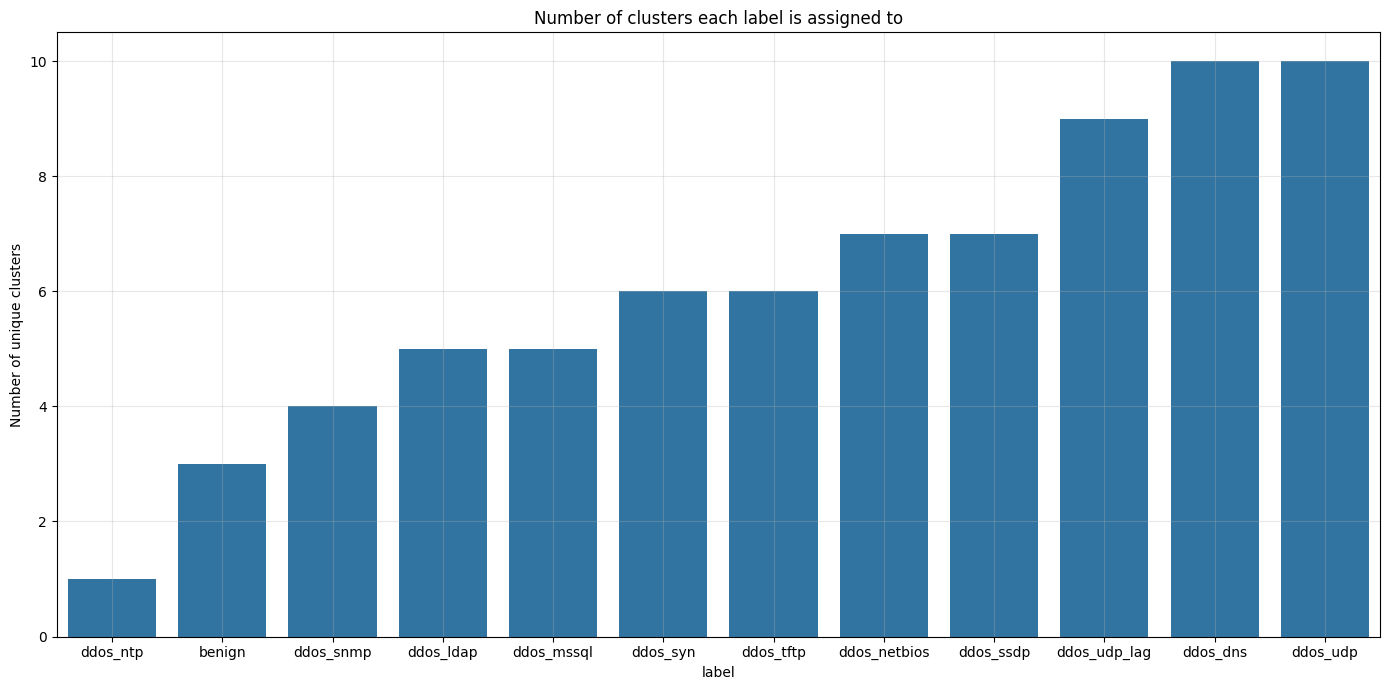

In [8]:
def plot_clusters_per_label(clusters_per_label):
    plt.figure(figsize=(14, 7))
    sns.barplot(x=clusters_per_label.index, y=clusters_per_label.values)

    plt.title('Number of clusters each label is assigned to')
    plt.xlabel('label')
    plt.ylabel('Number of unique clusters')
    
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

clusters_per_label = df_pd.groupby('label')['cluster'].nunique().sort_values()
plot_clusters_per_label(clusters_per_label)

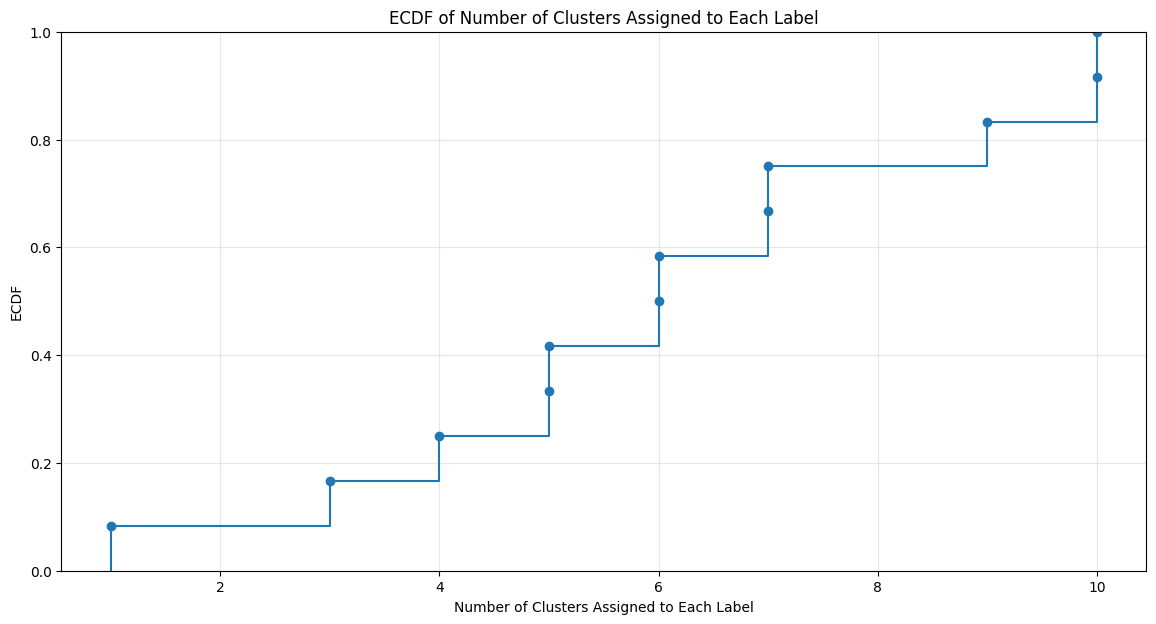

In [9]:
def plot_ECDF_number_of_clusters_per_label(clusters_per_label):
    plt.figure(figsize=(14, 7))
    sns.ecdfplot(clusters_per_label, marker='o')

    plt.title('ECDF of Number of Clusters Assigned to Each Label')
    plt.xlabel('Number of Clusters Assigned to Each Label')
    plt.ylabel('ECDF')
    plt.grid(alpha=0.3)
    plt.show()

plot_ECDF_number_of_clusters_per_label(clusters_per_label)

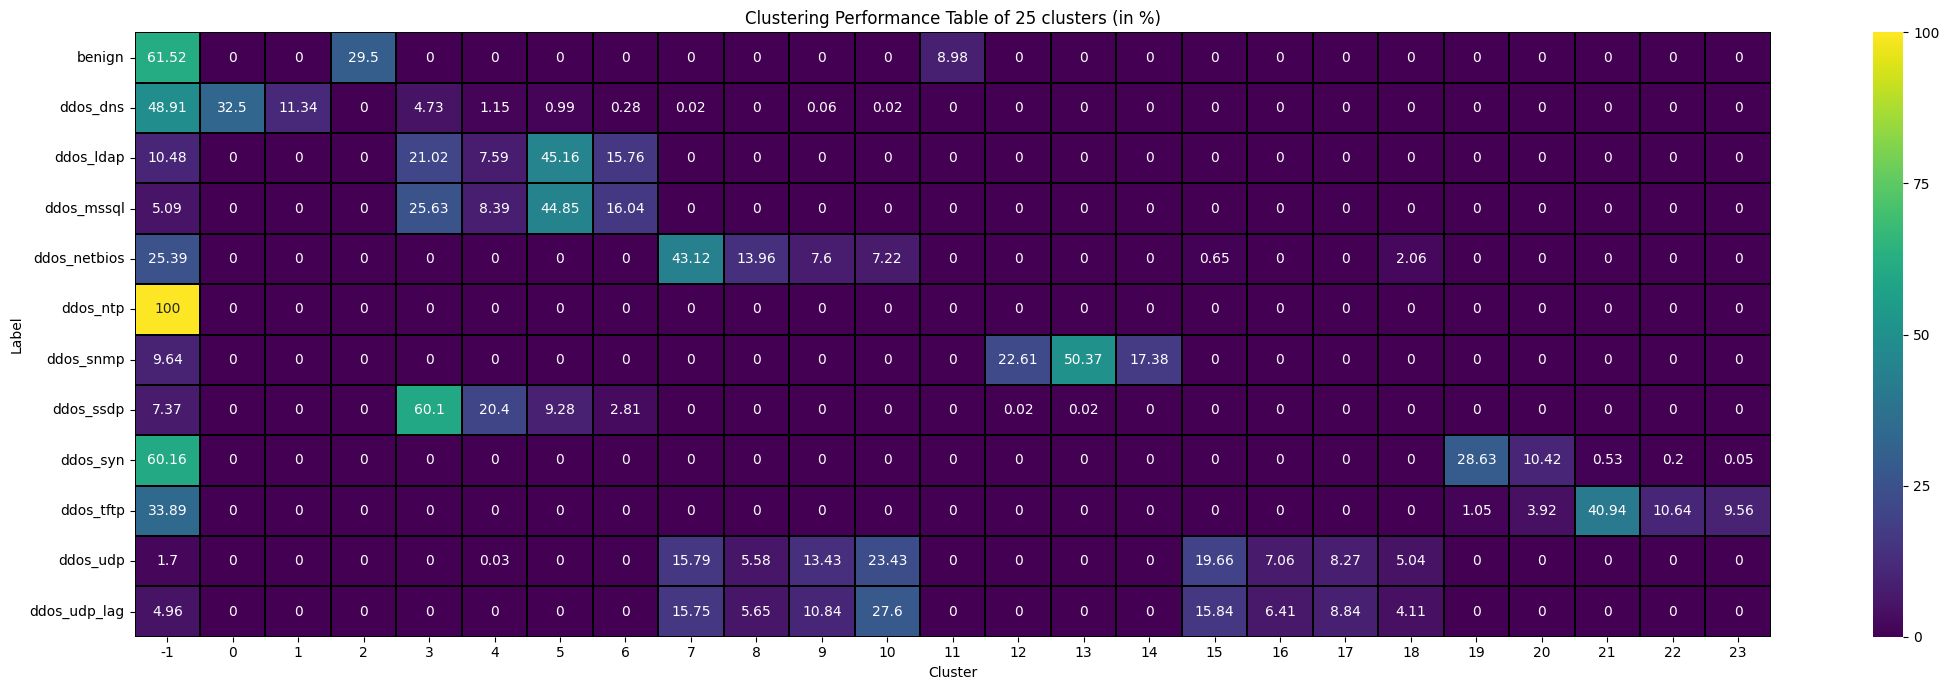

In [10]:
def plot_label_cluster_heatmap(cluster_labels, true_labels, normalize=True):
    df = pd.DataFrame({"label": true_labels,"cluster": cluster_labels})
    table = (df.groupby("label")["cluster"].value_counts().unstack(fill_value=0))

    if normalize:
        table = table.div(table.sum(axis=1), axis=0) *100

    plt.figure(figsize=(22,7))
    sns.heatmap(table, 
                cmap="viridis", 
                cbar=True, 
                cbar_kws={"ticks": np.linspace(0, 100 if normalize else table.values.max(), 5)}, 
                vmin=0, 
                vmax=100 if normalize else table.values.max(), 
                linewidths=0.1, 
                linecolor='black', 
                fmt="", 
                annot=table.map(lambda v: f"{v:.2f}".rstrip('0').rstrip('.')) if normalize else table,
                annot_kws={"size": 10})

    plt.xlabel("Cluster")
    plt.ylabel("Label")
    if normalize:
        plt.title(f"Clustering Performance Table of {len(np.unique(cluster_labels))} clusters (in %)")
    else:
        plt.title(f"Clustering Performance Table of {len(np.unique(cluster_labels))} clusters (num of samples)")

    plt.tight_layout()
    plt.show()

plot_label_cluster_heatmap(df_pd["cluster"],df_pd["label"],True)

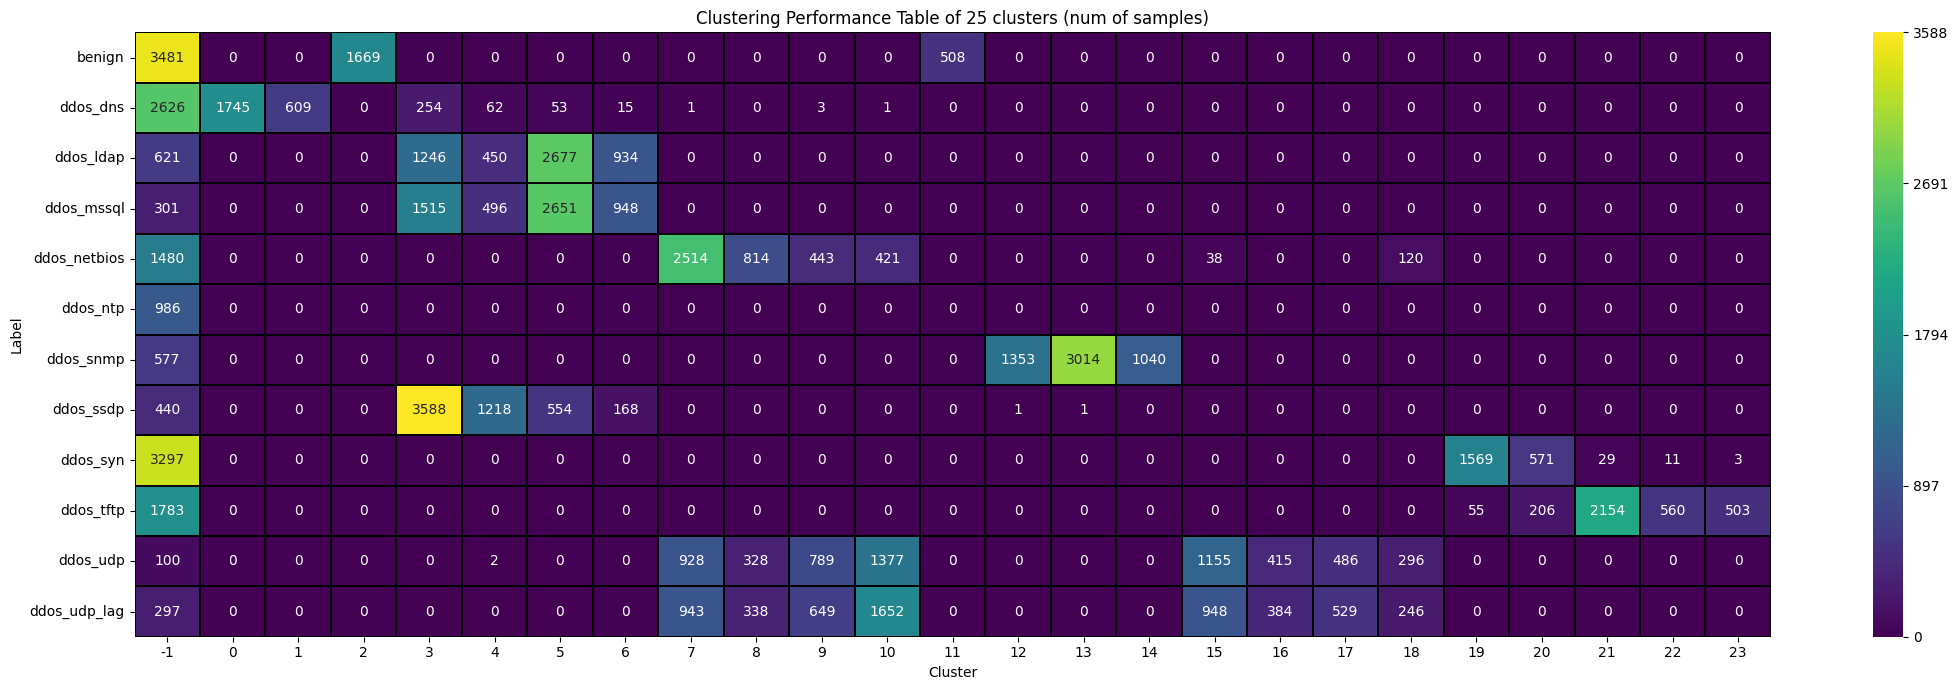

In [11]:
plot_label_cluster_heatmap(df_pd["cluster"],df_pd["label"],False)

# Analysis
1. a) How Traffic is Distributed (ECDF Analysis):
    - The analysis demonstrates that traffic is not uniformly distributed across clusters.
    - ECDF Analysis: The ECDF plot reveals significant concentration of classes within a limited number of clusters.
    - Fragmentation: There is variability in how classes are assigned across 25 clusters, with DBSCAN identifying distinct density-based regions in the network traffic data.

2. b) Cluster Purity and Dominant Patterns:
    - High Purity Clusters:
        - Cluster 0: Highly specific to ddos_dns (32.5% of this attack class);
        - Cluster 3: Mixed attack types (ddos_dns, ddos_ldap, ddos_mssql, ddos_ssdp) showing reflection/amplification attack grouping;
        - Cluster 7: Dominated by ddos_netbios (43.12%);
        - Cluster 13: Absolute dominance of ddos_snmp label (50.37%).
    - Low Purity/Mixed Clusters:
        - Clusters 4-5-6: They are all mixed clusters containing ddos_ldap, ddos_mssql and ddos_ssdp;
        - Cluster 8: Mixed cluster containing ddos_netbios, ddos_ldap, ddos_mssql;
        - Cluster 9: Mixed cluster containing ddos_netbios, ddos_ldap, ddos_mssql.

3. c) Overlap between classes and Benign/Malicious separation:
    - The heatmap analysis shows that some clusters are composed almost exclusively of a single attack class (e.g., ddos_dns in cluster 0), while others present a greater mix of different classes.
    - Mixed clusters (such as 3, 4, 5, 6, 8, 9) highlight that some attack types share similar traffic patterns and are grouped together by DBSCAN, reflecting the similar nature of certain reflection/amplification attacks.
    - The presence of clusters with multiple labels suggests that the separation between benign and malicious traffic is not always clear-cut: some traffic characteristics can be shared between benign and attack flows, especially in the more "noisy" or border clusters.
    - Cluster -1 (noise) collects points that DBSCAN cannot assign to any dense cluster: here both benign and attack traffic are found, confirming that there are network behaviors not easily classifiable by clustering alone.
    - In summary, the heatmap confirms that the discrimination between benign and attack is not always binary, but depends on the specificity of the traffic features and the nature of the attacks present in the dataset.

# 2. Feature Importance Analysis.

### Permutation Importance

In [12]:
def permutation_importance_dbscan(checkpoint_file, df, features, true_labels, n_clusters, n_repeats=10, random_state=42, n_sample = None):
    if os.path.exists(checkpoint_file):
        with open(checkpoint_file, "rb") as f:
            saved_info = pickle.load(f)
            results = saved_info["results"]
            baseline = saved_info["baseline"]
            rng = np.random.default_rng()
            rng.bit_generator.state = saved_info["rng_state"]
            n_f = len(results["features"])
            print(f"Checkpoint found. Feature processed: {n_f}")
    else:
        rng = np.random.default_rng(random_state)
        dbscan_baseline = db=DBSCAN(eps=best_eps, min_samples=best_minsamples, algorithm='ball_tree',n_jobs=-1)
        baseline_labels = dbscan_baseline.fit_predict(df)

        baseline = {
            "labels": baseline_labels,
            "ari": adjusted_rand_score(true_labels, baseline_labels),
            "ri": rand_score(true_labels, baseline_labels),
            "silhouette": silhouette_score(df, baseline_labels, sample_size=n_sample ),
        }

        results = {
            "features": [],
            "ari": [],
            "ri": [],
            "silhouette": [],
            "instability_scores": []
        }

    for j in range(df.shape[1]):
        if features[j] not in results["features"]:
            print(f"Iterating on {features[j]}")
            ari_scores = []
            ri_scores = []
            silhouette_scores = []
            instability_scores = []

            for l in range(n_repeats):
                df_perm = df.copy()
                rng.shuffle(df_perm[:, j])
                
                dbscan_perm = DBSCAN(eps=best_eps, min_samples=best_minsamples, algorithm='ball_tree',n_jobs=-1)
                perm_labels = dbscan_perm.fit_predict(df_perm)
                ari_scores.append(baseline["ari"] - adjusted_rand_score(true_labels, perm_labels))
                instability_scores.append( 1.0 - adjusted_rand_score(baseline["labels"], perm_labels) )
                ri_scores.append(baseline["ri"] - rand_score(true_labels, perm_labels))
                silhouette_scores.append(baseline["silhouette"] - silhouette_score(df_perm, perm_labels, sample_size=n_sample))

            results["features"].append(features[j])
            results["ari"].append(np.mean(ari_scores))
            results["ri"].append(np.mean(ri_scores))
            results["silhouette"].append(np.mean(silhouette_scores))
            results["instability_scores"].append(np.mean(instability_scores))
        
            with open(checkpoint_file, "wb") as f:
                pickle.dump({"results": results, "baseline": baseline, "rng_state": rng.bit_generator.state}, f)
            print("Checkpoint saved")
    print(f"All saved")
    return results, baseline

In [13]:
results, baseline = permutation_importance_dbscan(checkpoint_file="./saved_results/feature_importance.pkl", df=df_pre_DBSCAN_np, features=df_pre_DBSCAN_pd.columns, true_labels=df_pd["label"], n_clusters=n_cluster, n_repeats=20, random_state=42, n_sample = 100)

Checkpoint found. Feature processed: 75
All saved


#### Interpretation of Feature Permutation Impacts
When evaluating the importance of a feature by permuting its values and observing the change in a performance metric 
- $\Delta > 0$ (Metric Worsens): The Feature is Useful. Permuting the values destroys the inherent structure of the data, leading to a drop in clustering quality. This indicates that the model relies on this feature to distinguish between patterns.
- $\Delta = 0$ (Metric Stays the Same): The Feature is Redundant/Useless. Scrambling the feature has no impact on the clustering results, meaning the algorithm is not utilizing this information to form clusters.
- $\Delta < 0$ (Metric Improves): The Feature is Noisy. Permuting the feature actually improves the clustering performance. This suggests the feature was acting as "noise" or a distractor, and its original presence was hindering the algorithm's ability to find clean, separate groups.

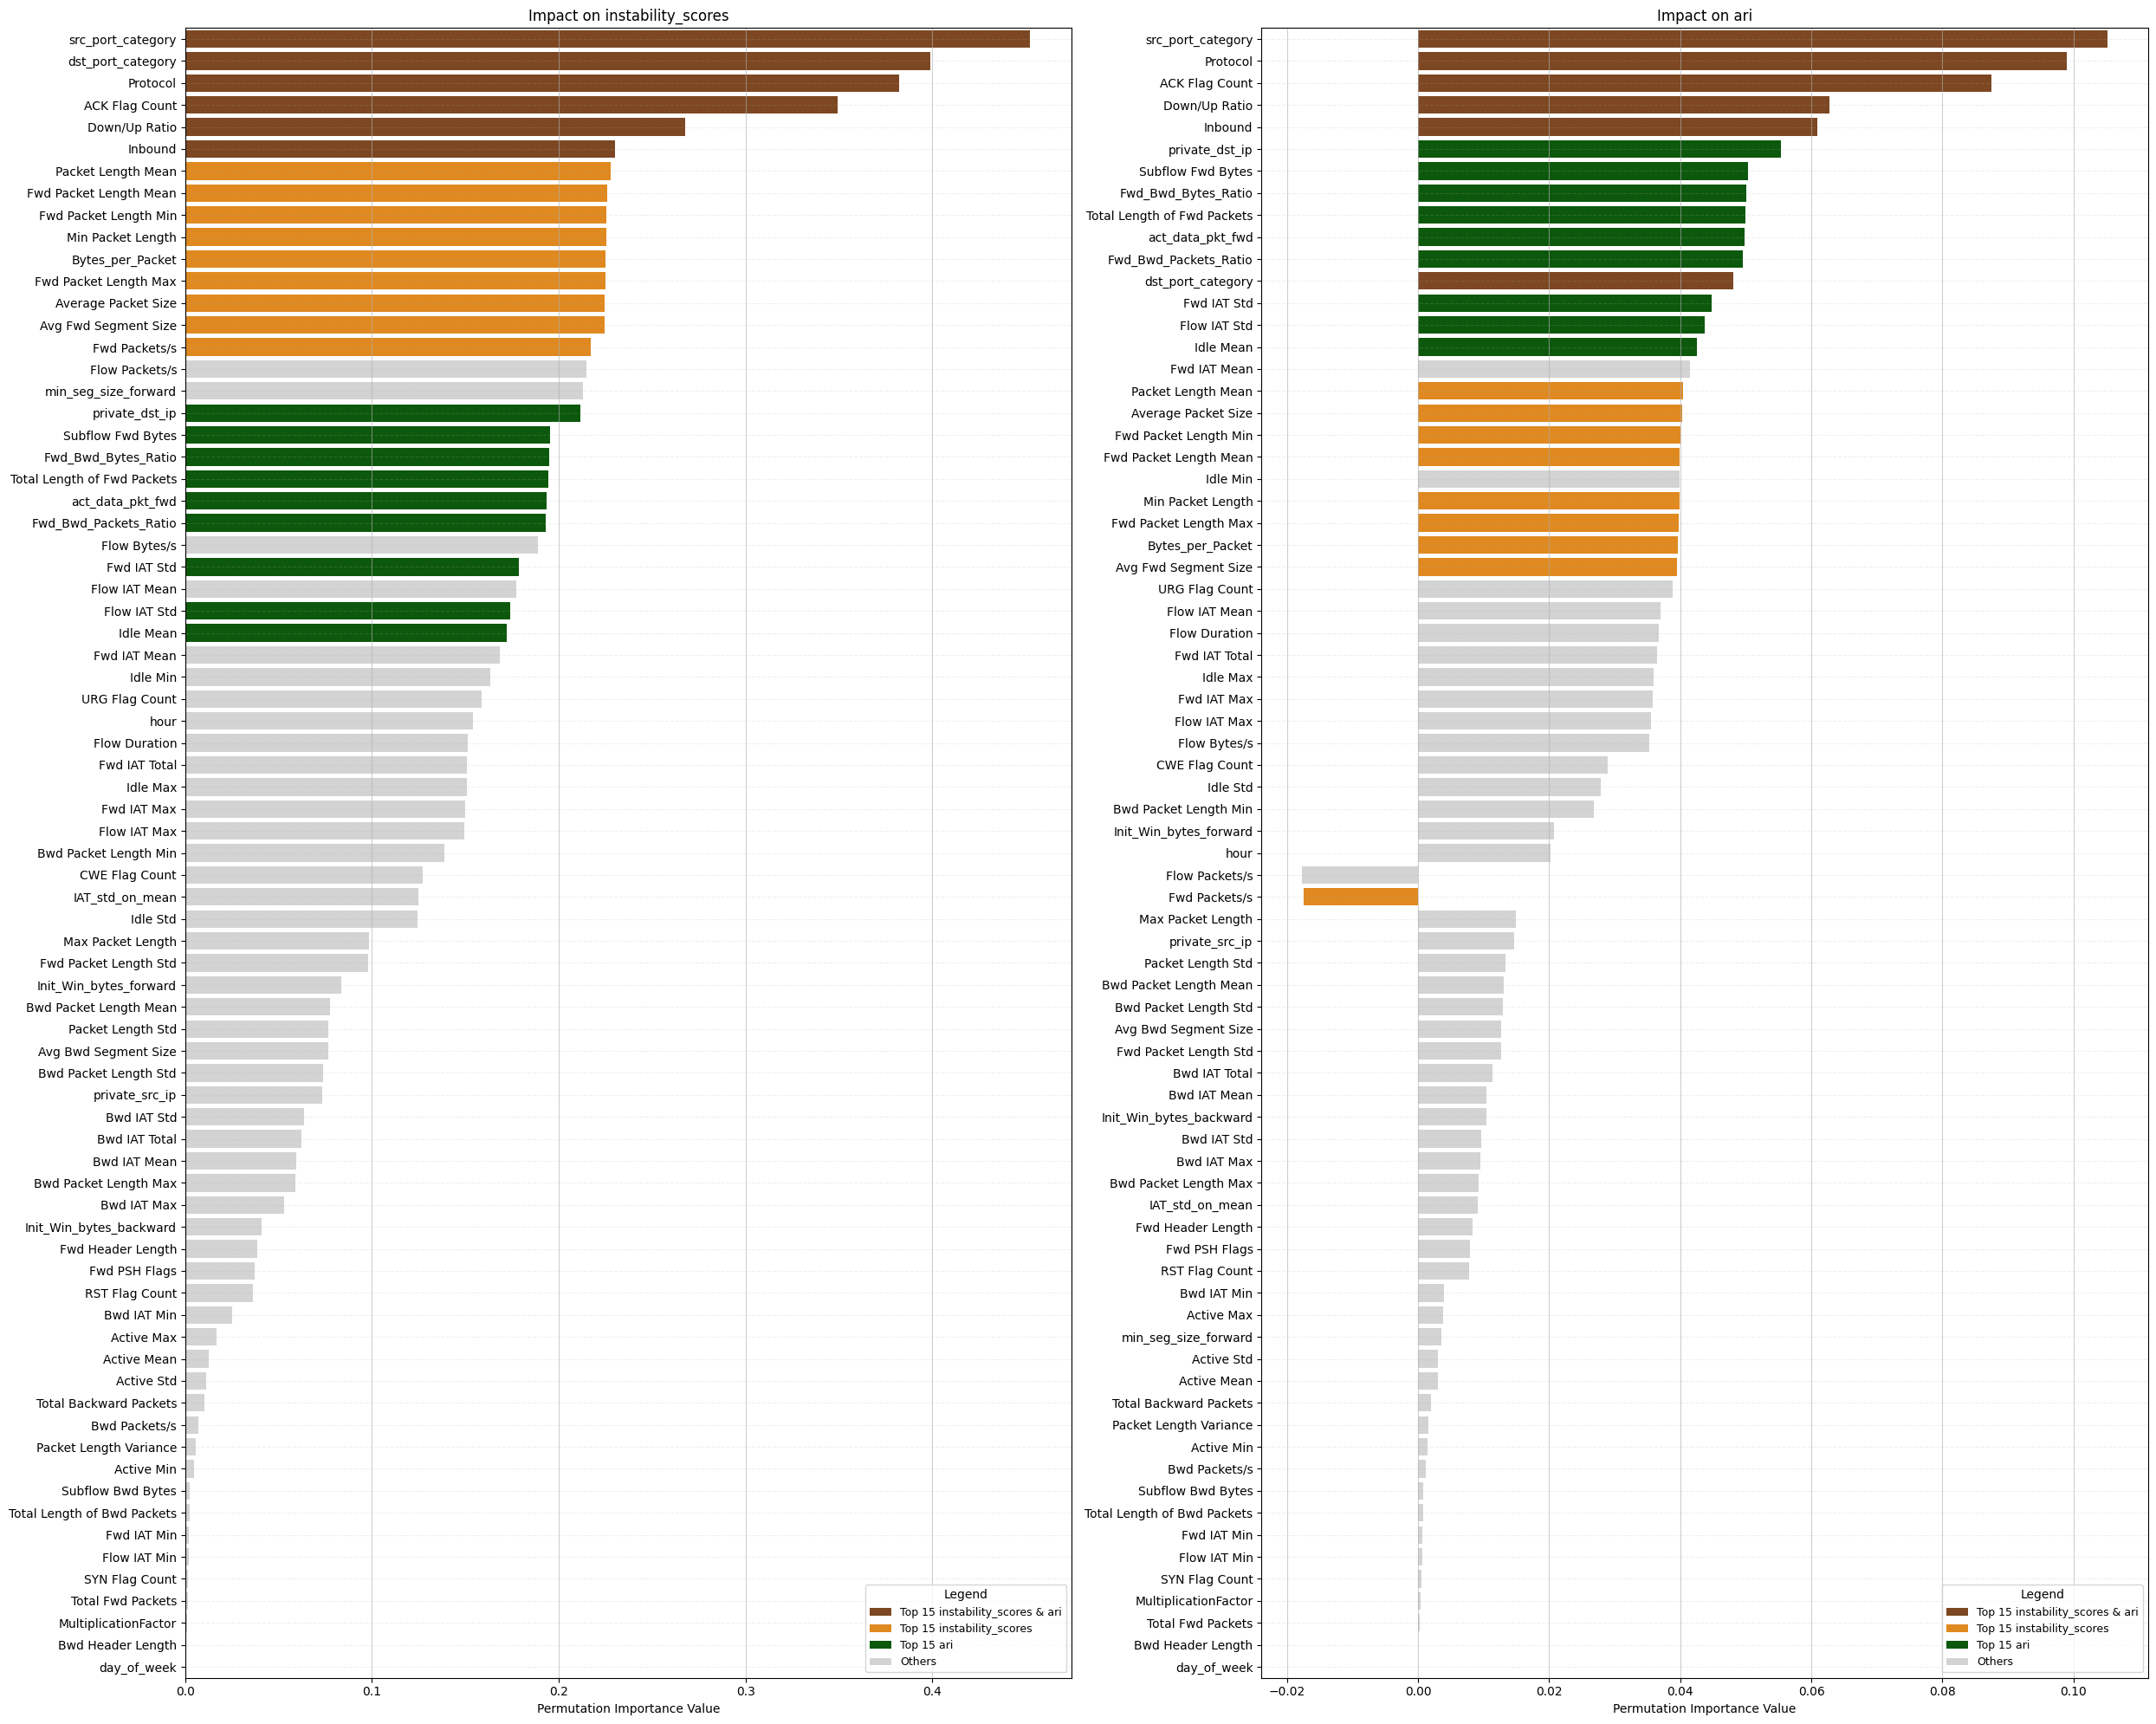

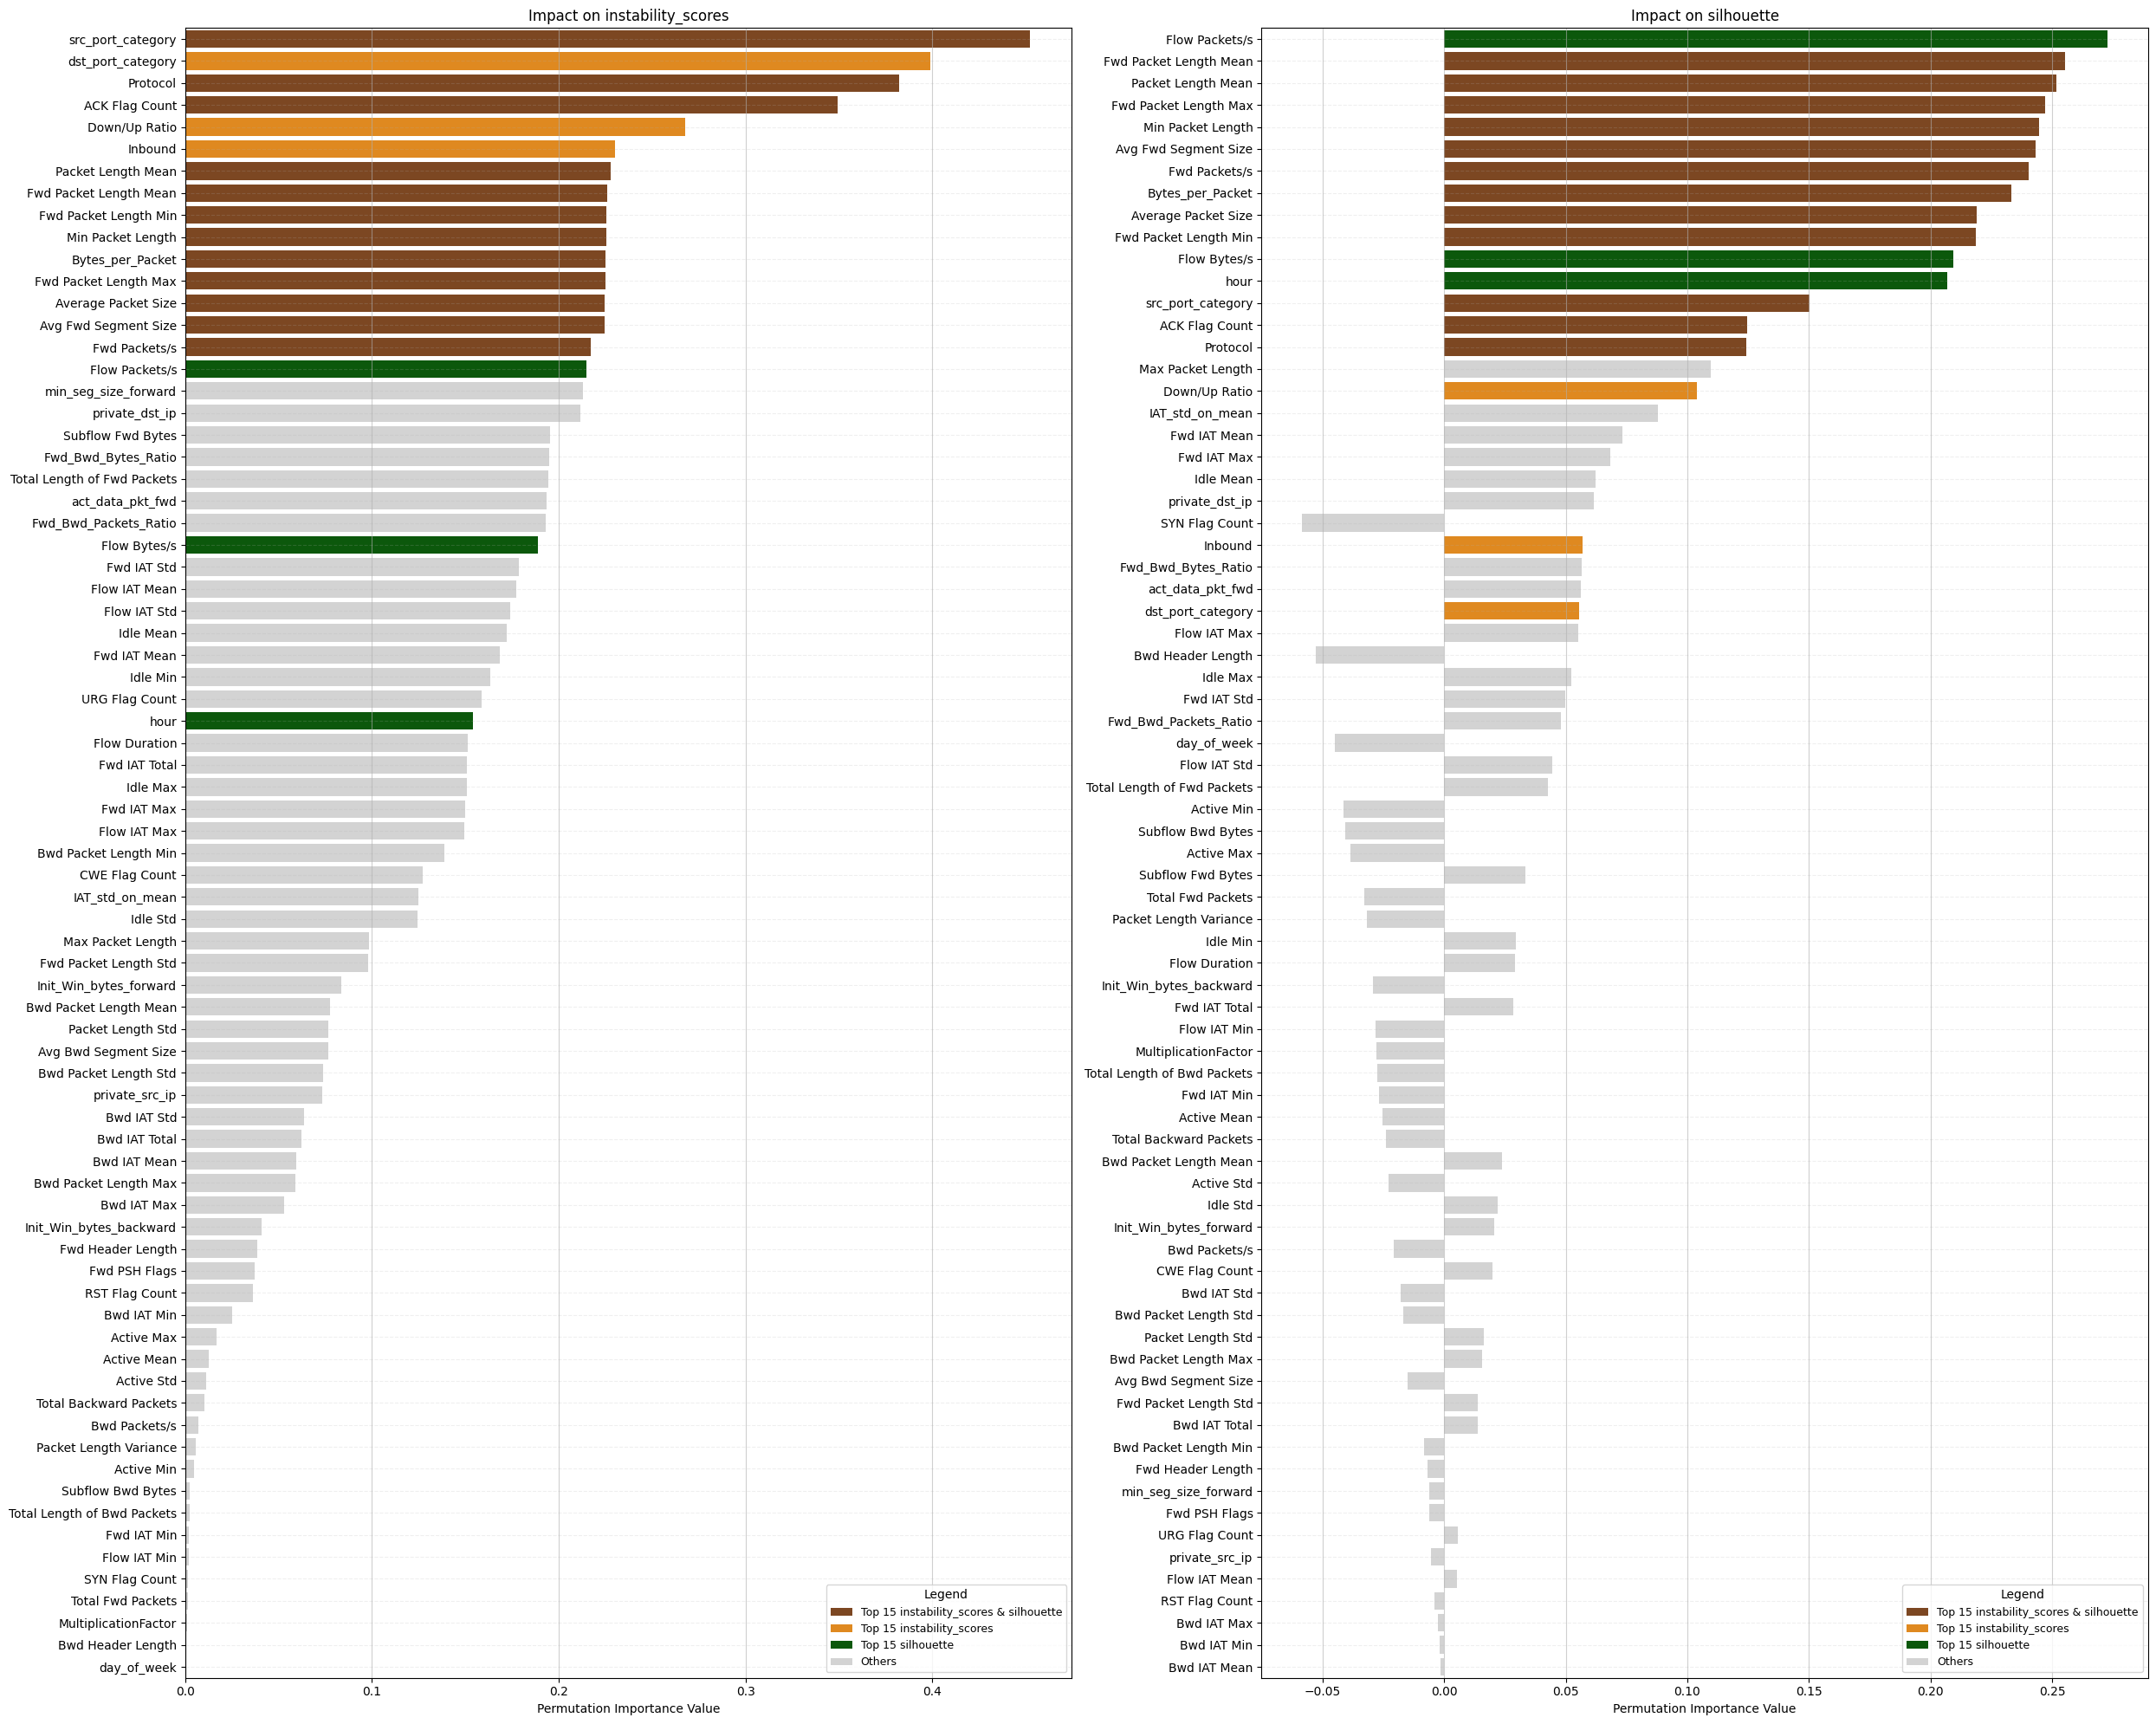

In [14]:
def plot_all_importances(results, metrics, top_n=10):
    
    df_tops = pd.DataFrame({"feature": results["features"], metrics[0]: results[metrics[0]],metrics[1]: results[metrics[1]]})
    top_1 = set(df_tops.nlargest(top_n, metrics[0])["feature"])
    top_2 = set(df_tops.nlargest(top_n, metrics[1])["feature"])
    top_common = top_1 & top_2
    
    def get_category(f):
        if f in top_common: return  f"Top {top_n} {metrics[0]} & {metrics[1]}"
        if f in top_1: return f"Top {top_n} {metrics[0]}"
        if f in top_2: return f"Top {top_n} {metrics[1]}"
        return "Others"

    palette = {f"Top {top_n} {metrics[0]} & {metrics[1]}": "#8B4513", f"Top {top_n} {metrics[0]}": "#FF8C00", f"Top {top_n} {metrics[1]}": "#006400", "Others": "#D3D3D3"}

    fig, axes = plt.subplots(len(metrics) // 2, 2, figsize=(25, 20))
    axes = axes.flatten()

    for i, metric in enumerate(metrics):
        df_plot = pd.DataFrame({"feature":  results["features"],"importance": results[metric],"Category": [get_category(f) for f in  results["features"]]})
        
        df_plot = df_plot.reindex(df_plot['importance'].abs().sort_values(ascending=False).index)

        sns.barplot(data=df_plot,y="feature",x="importance",hue="Category",palette=palette,ax=axes[i],hue_order= list(palette.keys()))

        axes[i].set_title(f"Impact on {metric}")
        axes[i].set_xlabel("Permutation Importance Value")
        axes[i].set_ylabel("")
        axes[i].grid(axis='x', alpha=0.6)
        axes[i].grid(axis='y', linestyle = '--', alpha=0.2)
        axes[i].legend(title=f"Legend", loc='lower right', fontsize=9)

    plt.tight_layout()
    plt.show()
plot_all_importances(results,["instability_scores","ari"], top_n=15)
plot_all_importances(results,["instability_scores","silhouette"], top_n=15)

# Analysis of Instability Scores
The Instability Score identifies which features are foundational to the algorithm's grouping logic. A high score indicates that the feature is a primary driver of cluster formation.

- Primary Network Control Features: The ACK Flag Count, Protocol, and Inbound status emerge as the most critical features for cluster stability. The high instability values for these variables suggest they act as the primary discriminators for the DBSCAN algorithm, likely separating traffic based on connection types and directional flow.

- Payload and Packet Dynamics: Features such as Bwd Packet Length Std, Bwd Packet Length Max, and Avg Bwd Segment Size show significant impact. This indicates that the variance and volume of data returning from the destination are essential for defining the "shape" of the clusters.

- Temporal and Flow Statistics: Flow IAT Std (Inter-Arrival Time) and Idle Std exhibit high importance. The algorithm relies heavily on these timing patterns to distinguish between different types of network behavior, such as persistent connections versus bursty or automated traffic.

- Throughput Metrics: Flow Bytes/s and Flow Duration are highlighted as key discriminators (indicated in green). Their removal significantly alters the resulting clusters, confirming that session density and duration are fundamental clustering criteria for this dataset.

Correlation with ARI (Adjusted Rand Index)
The comparison between Instability Scores and Impact on ARI provides a validation of the model's consistency.

- Metric Convergence: There is a strong alignment between features that provide internal stability (Instability) and those that align with the ground truth labels (ARI). Specifically, ACK Flag Count and Protocol dominate both metrics, confirming that the algorithm is capturing the most meaningful partitions in the data.

- Feature Robustness: The top 10 features identified in the Instability chart (marked in dark brown, orange, and green) remain the most influential in the ARI chart. This suggests that the structural clusters found by the algorithm are not arbitrary but are highly representative of the underlying data classes.

# 3. Attack Pattern Investigation.

### a)  Can you identify sub-attacks which belongs to the same class but have different patterns? Which feature contributes to your identification? 

Yes, the clustering clearly reveals that **sub-attacks belonging to the same DDoS class exhibit different behavioral patterns**, as they are mapped to **distinct clusters**.
1. To investigate sub-attack patterns, we analyzed the standardized mean feature values for each cluster (median values showed the same trends), focusing on features with the highest inter-cluster variance.
2. Features that showed the same values across all clusters, were excluded from the analysis, as they do not contribute to the characterization of the different sub-attack groups.
3. Clusters representing less than ~10% of the samples were excluded from the analysis, as they likely correspond to noise, outliers, or rare behaviors that do not significantly contribute to the dominant attack patterns

In [15]:
def getClassDf(ddos_class):
    df_clustered = df_pd.copy()

    df_ddos_class = df_clustered[df_clustered["label"] == ddos_class].copy().reset_index(drop=True)
    df_ddos_class = df_ddos_class.drop(columns="label")
    
    # Save cluster column before filtering
    cluster_col = df_ddos_class["cluster"].copy()
    
    # Filter features but exclude cluster from the filter
    features = df_ddos_class.drop(columns="cluster")
    features = features.loc[:, features.nunique() > 1]

    df_ddos_class_scaled = pd.DataFrame(StandardScaler().fit_transform(features), columns=features.columns)
    df_ddos_class_scaled['cluster'] = cluster_col
    
    # For df_ddos_class, keep only the filtered features + cluster
    df_ddos_class = features.copy()
    df_ddos_class['cluster'] = cluster_col
    
    return df_ddos_class, df_ddos_class_scaled

In [16]:
def plotClusterSummary(df, label):
    counts = df["cluster"].value_counts().sort_index()
    percentages = (df["cluster"].value_counts(normalize=True).sort_index() * 100)
    
    plt.figure(figsize=(14, 6))
    
    ax = sns.barplot(x=counts.index, y=counts.values, palette='viridis', hue=counts.index, legend=False)
    
    labels = []
    for i in range(len(counts)):
        c = counts.values[i]
        p = percentages.values[i]
        testo = f'{int(c)}\n({p:.1f}%)'
        labels.append(testo)
        
    for i, container in enumerate(ax.containers):
        ax.bar_label(container, labels=[labels[i]], padding=3)

    plt.title(f"Sample Distribution by Cluster ({label})")
    plt.xlabel("Cluster")
    plt.ylabel("Number of Samples")
    plt.ylim(0, max(counts.values) * 1.15) 
    plt.grid(axis='y', linestyle='--', alpha=0.6)
    
    plt.tight_layout()
    plt.show()

In [17]:
def drop_clusters(df, toDrop):
    for id in toDrop:
        df = df[df["cluster"] != id].reset_index(drop=True)
    return df

In [18]:
def plotMeanFeaturesPerCluster(df_s, mesure, ddos_class):
    if mesure == "Mean":
        df_mesure = df_s.groupby("cluster").mean().reset_index()
        sorted_features = df_s.groupby("cluster").mean().var().sort_values(ascending=False).index
    elif mesure == "Median":
        df_mesure = df_s.groupby("cluster").median().reset_index()
        sorted_features = df_s.groupby("cluster").median().var().sort_values(ascending=False).index
    else:
        print("Mesure invalid")
        return
    
    df_melted = df_mesure.melt(id_vars="cluster", var_name="Feature", value_name="Standardized Value")

    plt.figure(figsize=(10, 25)) 

    sns.barplot(data=df_melted, x="Standardized Value", y="Feature", hue="cluster", palette="viridis", order=sorted_features)

    plt.axvline(0, color='#333333', linewidth=2, label='Global Average') 
    plt.axvline(x=1, color='firebrick', linestyle='--', linewidth=1, alpha=0.7)
    plt.axvline(x=-1, color='firebrick', linestyle='--', linewidth=1, alpha=0.7)
    plt.axvline(x=0.5, color='gray', linestyle=':', linewidth=1, alpha=0.5)
    plt.axvline(x=-0.5, color='gray', linestyle=':', linewidth=1, alpha=0.5)
    plt.axvline(x=2, color='gray', linestyle='-.', linewidth=1, alpha=0.6)
    plt.axvline(x=-2, color='gray', linestyle='-.', linewidth=1, alpha=0.6)

    plt.title(f"{mesure} Values Feature per Cluster of {ddos_class}")
    plt.xlabel("Standardized Score")
    plt.ylabel("Features sorted by variance across cluster means")
    plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc='upper left')

    plt.grid(axis='y', alpha=0.6)
    plt.tight_layout()
    plt.show()

### Attack Pattern Investigation – ddos_ldap
The ddos_ldap attack class exhibits multiple distinct patterns as revealed by DBSCAN clustering. This indicates that LDAP-based DDoS attacks can manifest with varying network traffic characteristics. The analysis below explores how intensity and flow timing parameters create distinguishable sub-groups within this attack class. The corresponding code computes the clusters for ddos_ldap, visualizes their distribution, removes small/noisy clusters, and then analyzes the mean standardized feature values for each remaining cluster. The resulting plots highlight which features most differentiate the sub-patterns within ddos_ldap attacks.

In [19]:
df_ldap , df_ldap_scaled = getClassDf("ddos_ldap")

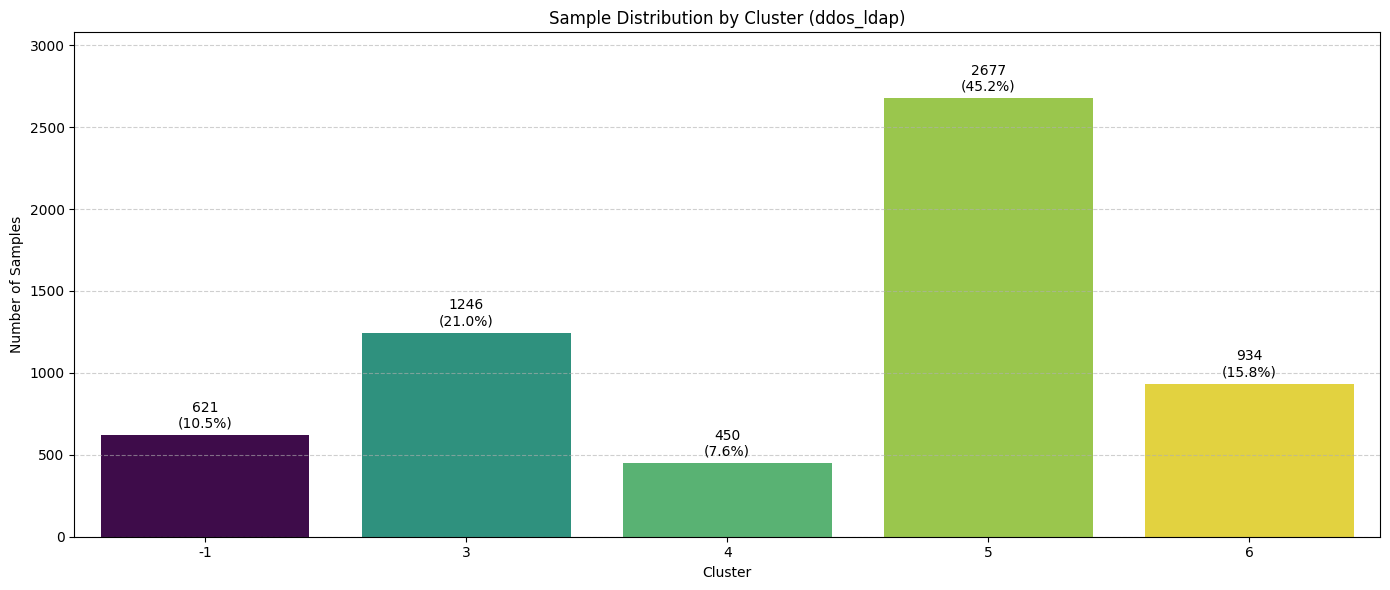

In [20]:
plotClusterSummary(df_ldap, "ddos_ldap")

In [21]:
toDrop = [-1,4]
df_ldap = drop_clusters(df_ldap, toDrop)
df_ldap_scaled = drop_clusters(df_ldap_scaled, toDrop)

In [22]:
df_ldap.groupby("cluster").agg(["mean", "std", "median"])

Protocol             Flow Duration                    \
            mean  std median          mean        std median   
cluster                                                        
3           17.0  0.0   17.0     13.743178  36.182845    2.0   
5           17.0  0.0   17.0      1.000000   0.000000    1.0   
6           17.0  0.0   17.0      1.000000   0.000000    1.0   

        Total Fwd Packets                  Total Backward Packets  ...  \
                     mean       std median                   mean  ...   
cluster                                                            ...   
3                2.006421  0.226637    2.0           1.000000e-12  ...   
5                2.000000  0.000000    2.0           1.000000e-12  ...   
6                2.000000  0.000000    2.0           1.000000e-12  ...   

        Fwd_Bwd_Packets_Ratio Fwd_Bwd_Bytes_Ratio                              \
                       median                mean           std        median   
cluster                                                                         
3                2.000000e+12        2.945888e+15  3.359727e+14  2.944000e+15   
5                2.000000e+12        2.931126e+15  5.972639e+13  2.944000e+15   
6                2.000000e+12        2.934921e+15  4.275206e+13  2.944000e+15   

        src_port_category             dst_port_category              
                     mean  std median              mean  std median  
cluster                                                              
3                     0.0  0.0    0.0               1.0  0.0    1.0  
5                     0.0  0.0    0.0               1.0  0.0    1.0  
6                     0.0  0.0    0.0               2.0  0.0    2.0  

[3 rows x 177 columns]

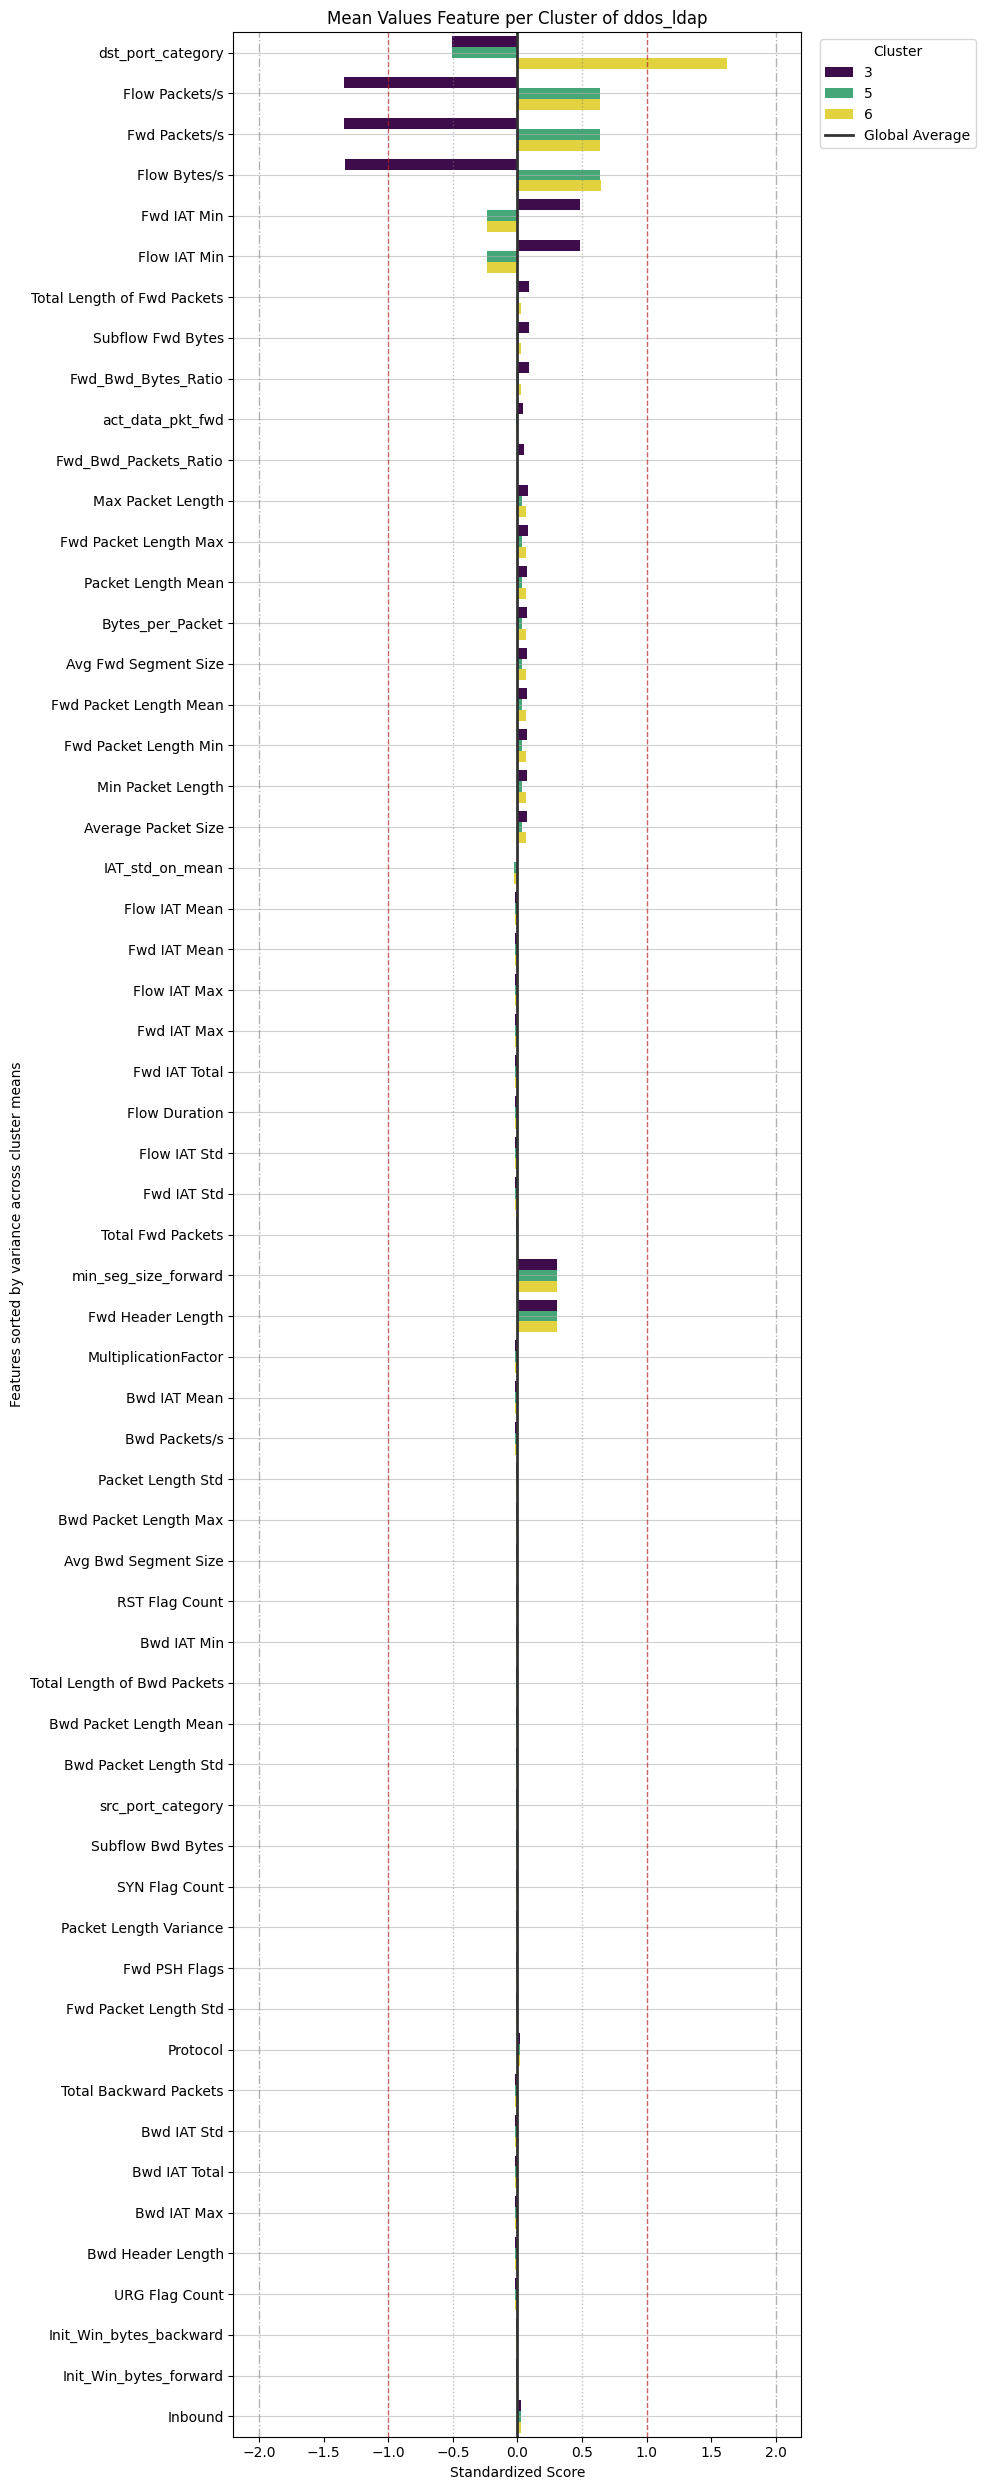

In [23]:
plotMeanFeaturesPerCluster(df_ldap_scaled, "Mean", "ddos_ldap")

### Attack Pattern Investigation – ddos_mssql
The ddos_mssql attack class also displays several distinct clustering patterns in the DBSCAN results, indicating that MSSQL-based DDoS attacks can have diverse network behaviors. The code extracts the ddos_mssql samples, visualizes their cluster distribution, and examines the mean and variance of features within each cluster. The analysis and plots show that features related to flow duration and total forwarded packets are key to distinguishing the sub-groups within ddos_mssql attacks.

In [24]:
df_mssql , df_mssql_scaled = getClassDf("ddos_mssql")

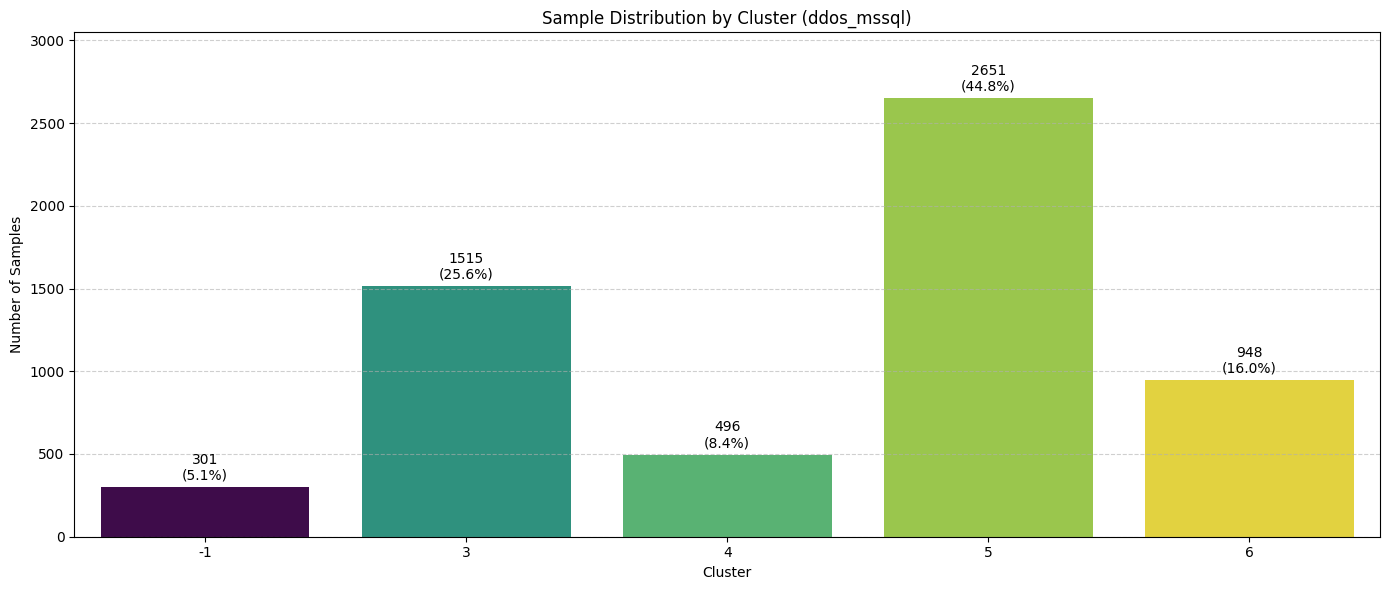

In [25]:
plotClusterSummary(df_mssql,"ddos_mssql")

In [26]:
toDrop = [-1,4]
df_mssql = drop_clusters(df_mssql, toDrop)
df_mssql_scaled = drop_clusters(df_mssql_scaled, toDrop)

In [27]:
df_mssql_scaled.groupby("cluster").agg(["mean", "std", "median"])

Protocol                Flow Duration                      \
             mean  std    median          mean       std    median   
cluster                                                              
3        0.017989  0.0  0.017989     -0.016637  0.000018 -0.016645   
5        0.017989  0.0  0.017989     -0.016646  0.000000 -0.016646   
6        0.017989  0.0  0.017989     -0.016646  0.000000 -0.016646   

        Total Fwd Packets                     Total Backward Packets  ...  \
                     mean       std    median                   mean  ...   
cluster                                                               ...   
3               -0.013004  0.000171 -0.013015              -0.013231  ...   
5               -0.013015  0.000000 -0.013015              -0.013231  ...   
6               -0.013015  0.000000 -0.013015              -0.013231  ...   

        Fwd_Bwd_Packets_Ratio Fwd_Bwd_Bytes_Ratio                      \
                       median                mean       std    median   
cluster                                                                 
3                   -0.034783            0.086331  1.169477  0.070295   
5                   -0.034783           -0.008364  0.388172  0.070295   
6                   -0.034783            0.001991  0.347864  0.070295   

        src_port_category                dst_port_category                 
                     mean  std    median              mean  std    median  
cluster                                                                    
3               -0.037574  0.0 -0.037574         -0.517205  0.0 -0.517205  
5               -0.037574  0.0 -0.037574         -0.517205  0.0 -0.517205  
6               -0.037574  0.0 -0.037574          1.643359  0.0  1.643359  

[3 rows x 192 columns]

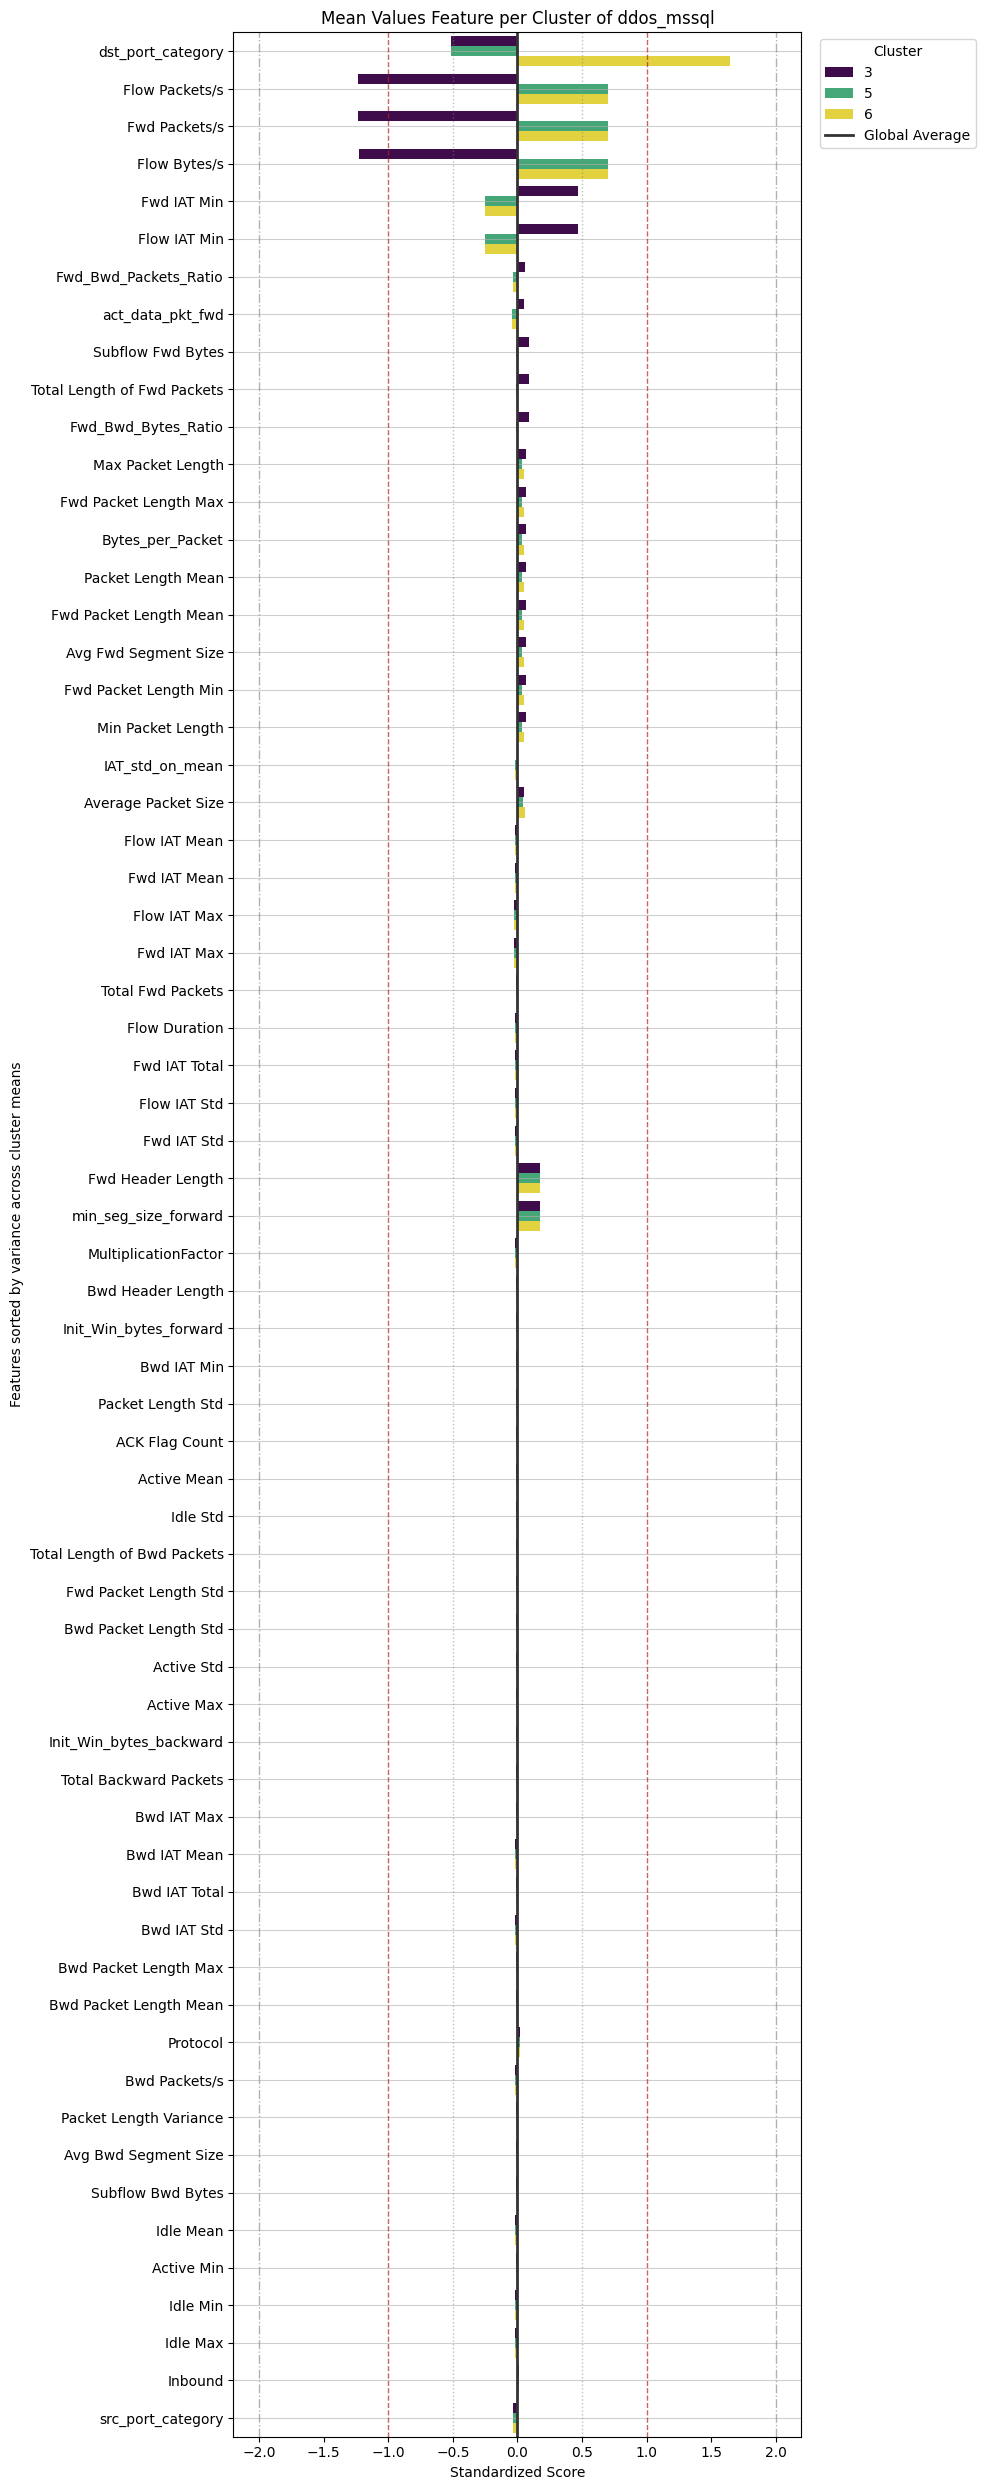

In [28]:
plotMeanFeaturesPerCluster(df_mssql_scaled, "Mean", "ddos_mssql")

### Attack Pattern Investigation – ddos_netbios
The ddos_netbios attack class shows a dispersed pattern across DBSCAN clusters, with some clusters containing only a small fraction of the total samples. The code selects ddos_netbios samples, visualizes their cluster distribution, removes clusters with low representation, and analyzes the standardized mean feature values for the main clusters. The resulting plots identify the key behavioral signatures that distinguish NetBIOS-based DDoS attacks from other types, focusing on features with the highest inter-cluster variance.

In [29]:
df_netbios , df_netbios_scaled = getClassDf("ddos_netbios")

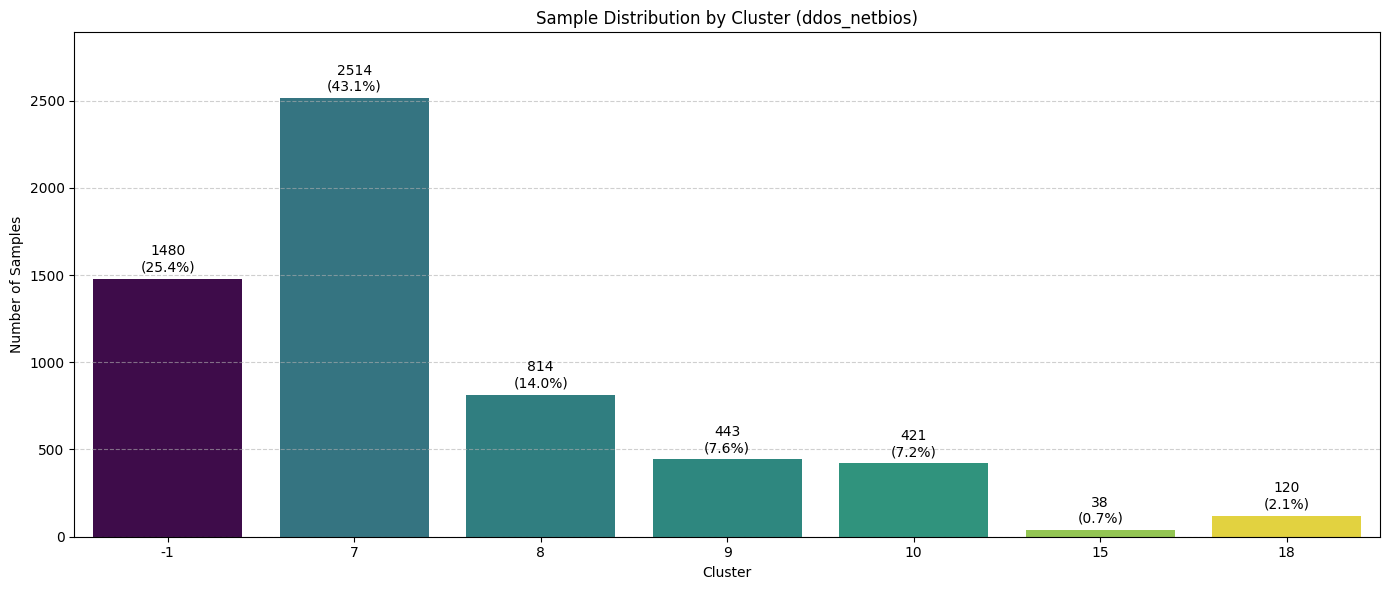

In [30]:
plotClusterSummary(df_netbios, "ddos_netbios")

In [31]:
toDrop = [-1, 9, 10, 15, 18]
df_netbios = drop_clusters(df_netbios, toDrop)
df_netbios_scaled = drop_clusters(df_netbios_scaled, toDrop)

In [32]:
df_netbios.groupby("cluster").agg(["mean", "std", "median"])

Protocol             Flow Duration             Total Fwd Packets       \
            mean  std median          mean  std median              mean  std   
cluster                                                                         
7           17.0  0.0   17.0           1.0  0.0    1.0               2.0  0.0   
8           17.0  0.0   17.0           1.0  0.0    1.0               2.0  0.0   

               Total Backward Packets  ... Fwd_Bwd_Packets_Ratio  \
        median                   mean  ...                median   
cluster                                ...                         
7          2.0           1.000000e-12  ...          2.000000e+12   
8          2.0           1.000000e-12  ...          2.000000e+12   

        Fwd_Bwd_Bytes_Ratio                             src_port_category  \
                       mean           std        median              mean   
cluster                                                                     
7              1.053657e+15  2.583340e+14  9.560000e+14               1.0   
8              1.040651e+15  2.277445e+14  9.490000e+14               1.0   

                    dst_port_category              
         std median              mean  std median  
cluster                                            
7        0.0    1.0               1.0  0.0    1.0  
8        0.0    1.0               2.0  0.0    2.0  

[2 rows x 153 columns]

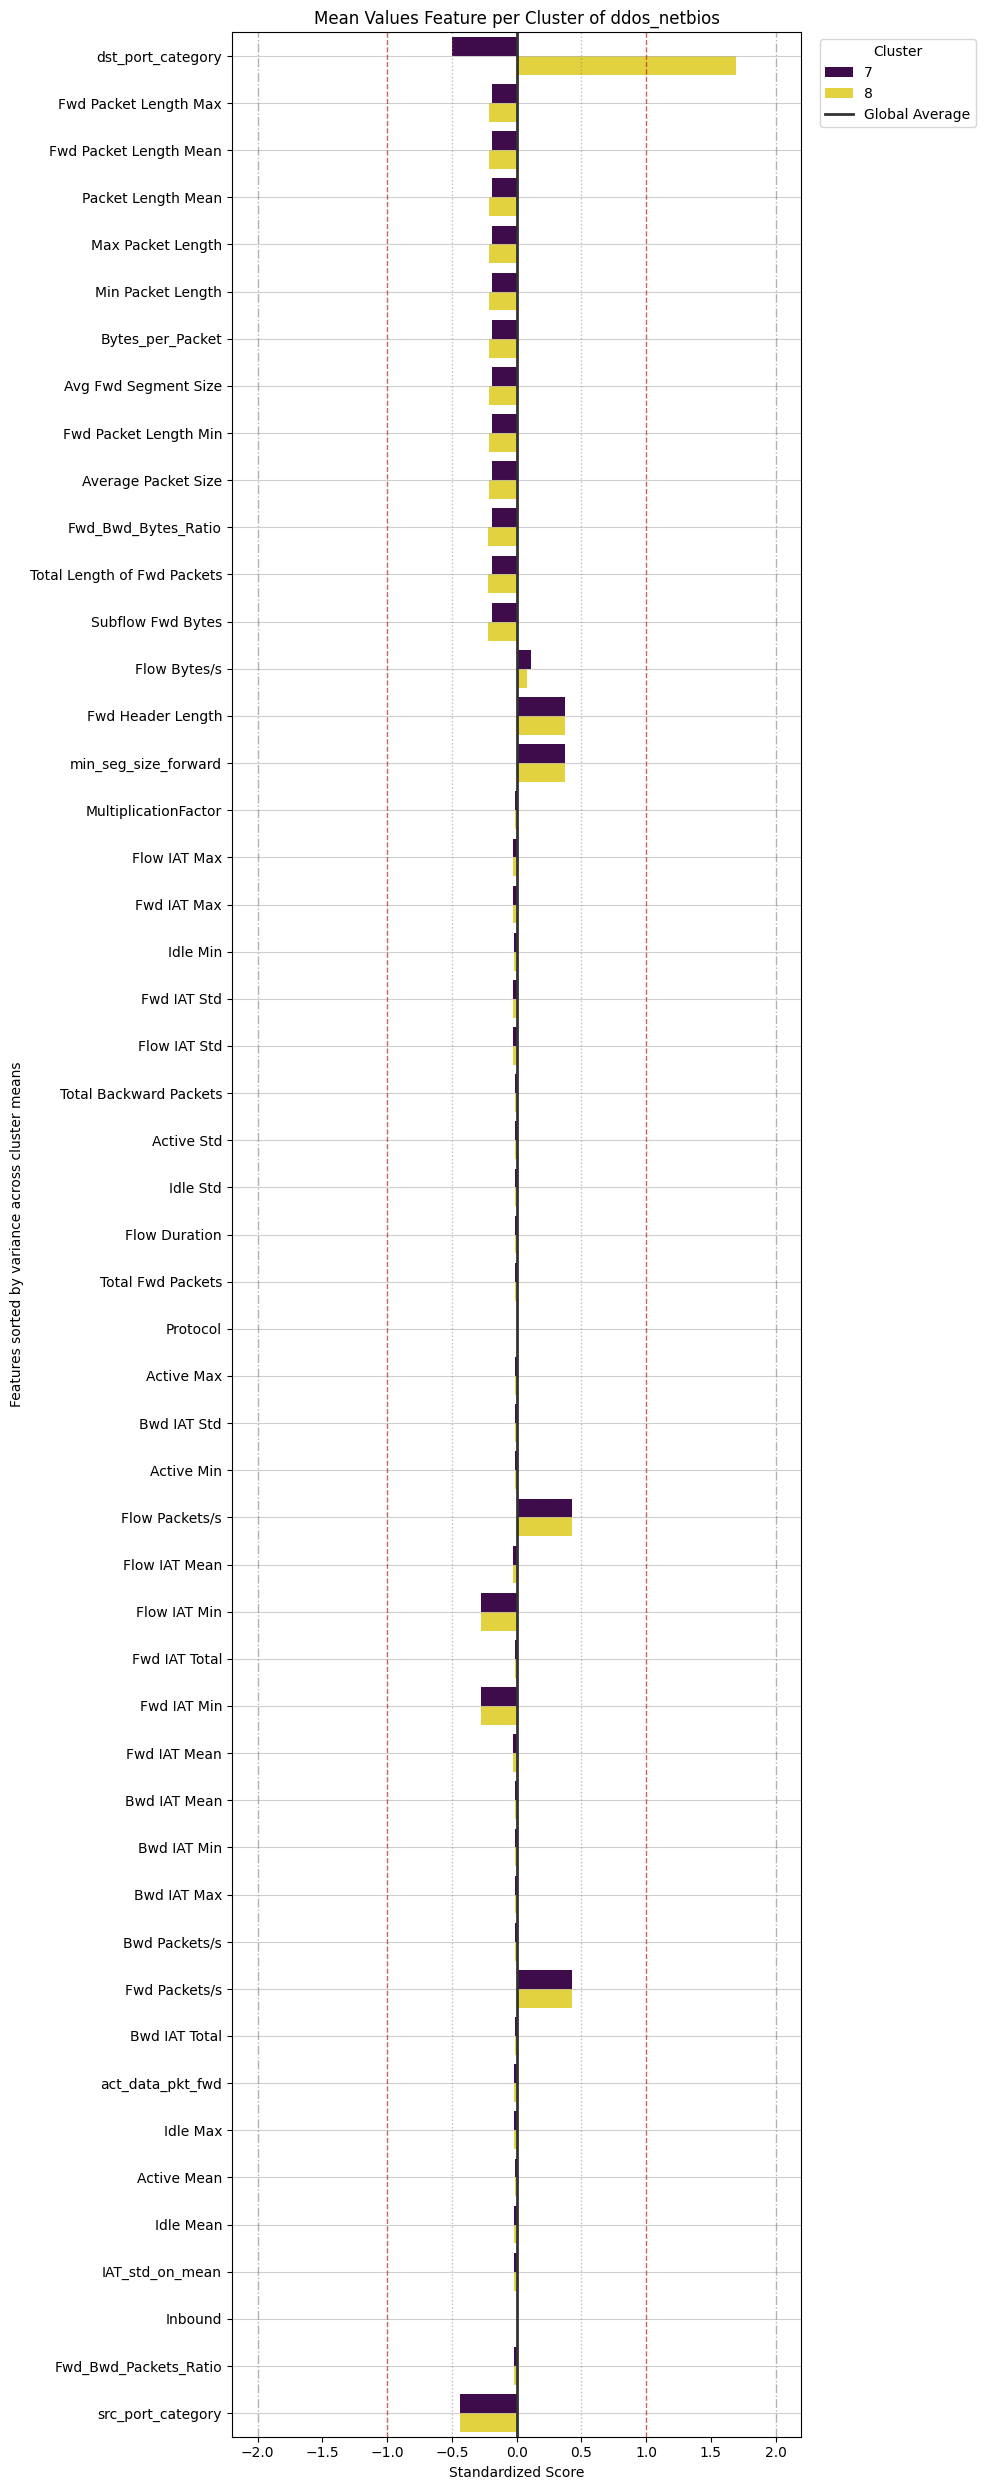

In [33]:
plotMeanFeaturesPerCluster(df_netbios_scaled, "Mean", "ddos_netbios")

### Attack Pattern Investigation – ddos_snmp
The ddos_snmp attack class is highly concentrated in specific DBSCAN clusters, with minimal noise or outlier points. The code extracts ddos_snmp samples, visualizes their cluster distribution, removes the dominant cluster to focus on sub-patterns, and analyzes the mean standardized feature values for the remaining clusters. The analysis and plots reveal that SNMP-based DDoS attacks exhibit consistent behavioral patterns, with clear separation from background traffic and other attack types, as highlighted by the most variant features across clusters.

In [34]:
df_snmp , df_snmp_scaled = getClassDf("ddos_snmp")

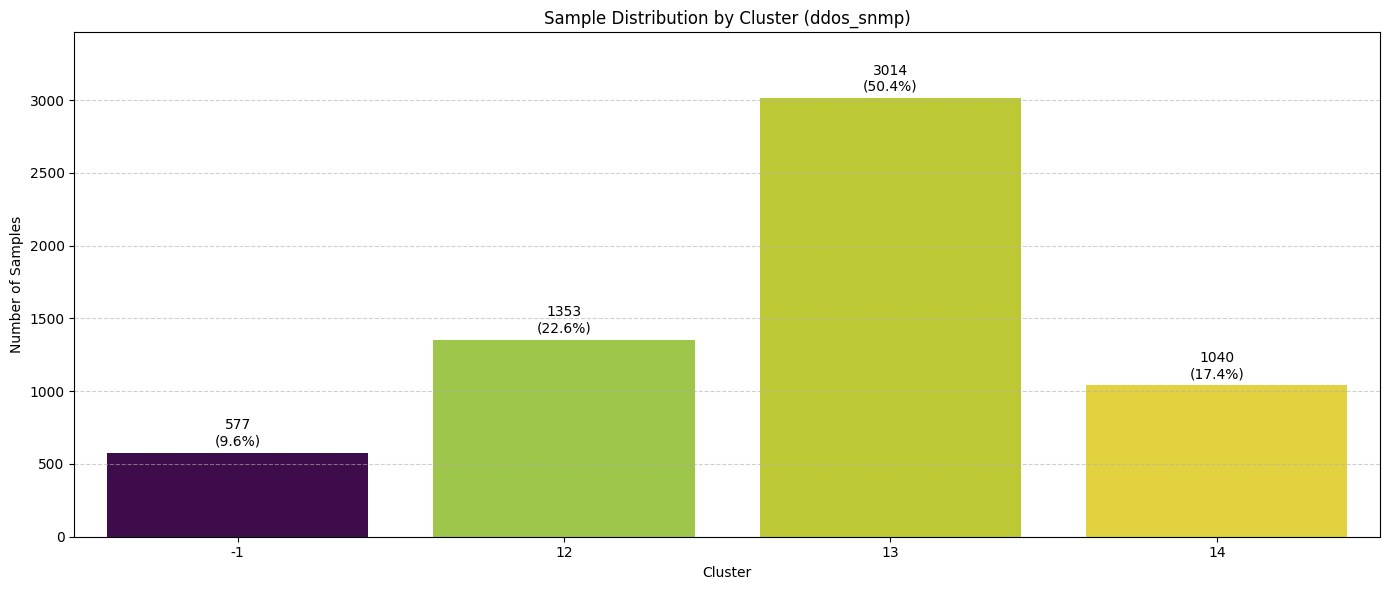

In [35]:
plotClusterSummary(df_snmp, "ddos_snmp")

In [36]:
toDrop = [-1]
df_snmp = drop_clusters(df_snmp, toDrop)
df_snmp_scaled = drop_clusters(df_snmp_scaled, toDrop)

In [37]:
df_snmp.groupby("cluster").agg(["mean", "std", "median"])

Flow Duration                   Total Fwd Packets                   \
                 mean        std median              mean       std median   
cluster                                                                      
12          23.194383  34.515517    2.0          2.017738  0.325874    2.0   
13           1.000000   0.000000    1.0          2.000000  0.000000    2.0   
14           1.000000   0.000000    1.0          2.000000  0.000000    2.0   

        Total Length of Fwd Packets                   Fwd Packet Length Max  \
                               mean        std median                  mean   
cluster                                                                       
12                       461.235772  76.447055  458.0            228.626755   
13                       458.270073  19.540491  458.0            229.135036   
14                       458.505769  22.185888  458.0            229.252885   

         ... IAT_std_on_mean Fwd_Bwd_Packets_Ratio                \
         ...          median                  mean           std   
cluster  ...                                                       
12       ...             0.0          2.017738e+12  3.258742e+11   
13       ...             0.0          2.000000e+12  0.000000e+00   
14       ...             0.0          2.000000e+12  0.000000e+00   

                      Fwd_Bwd_Bytes_Ratio                              \
               median                mean           std        median   
cluster                                                                 
12       2.000000e+12        4.612358e+14  7.644705e+13  4.580000e+14   
13       2.000000e+12        4.582701e+14  1.954049e+13  4.580000e+14   
14       2.000000e+12        4.585058e+14  2.218589e+13  4.580000e+14   

        dst_port_category              
                     mean  std median  
cluster                                
12                    1.0  0.0    1.0  
13                    1.0  0.0    1.0  
14                    2.0  0.0    2.0  

[3 rows x 102 columns]

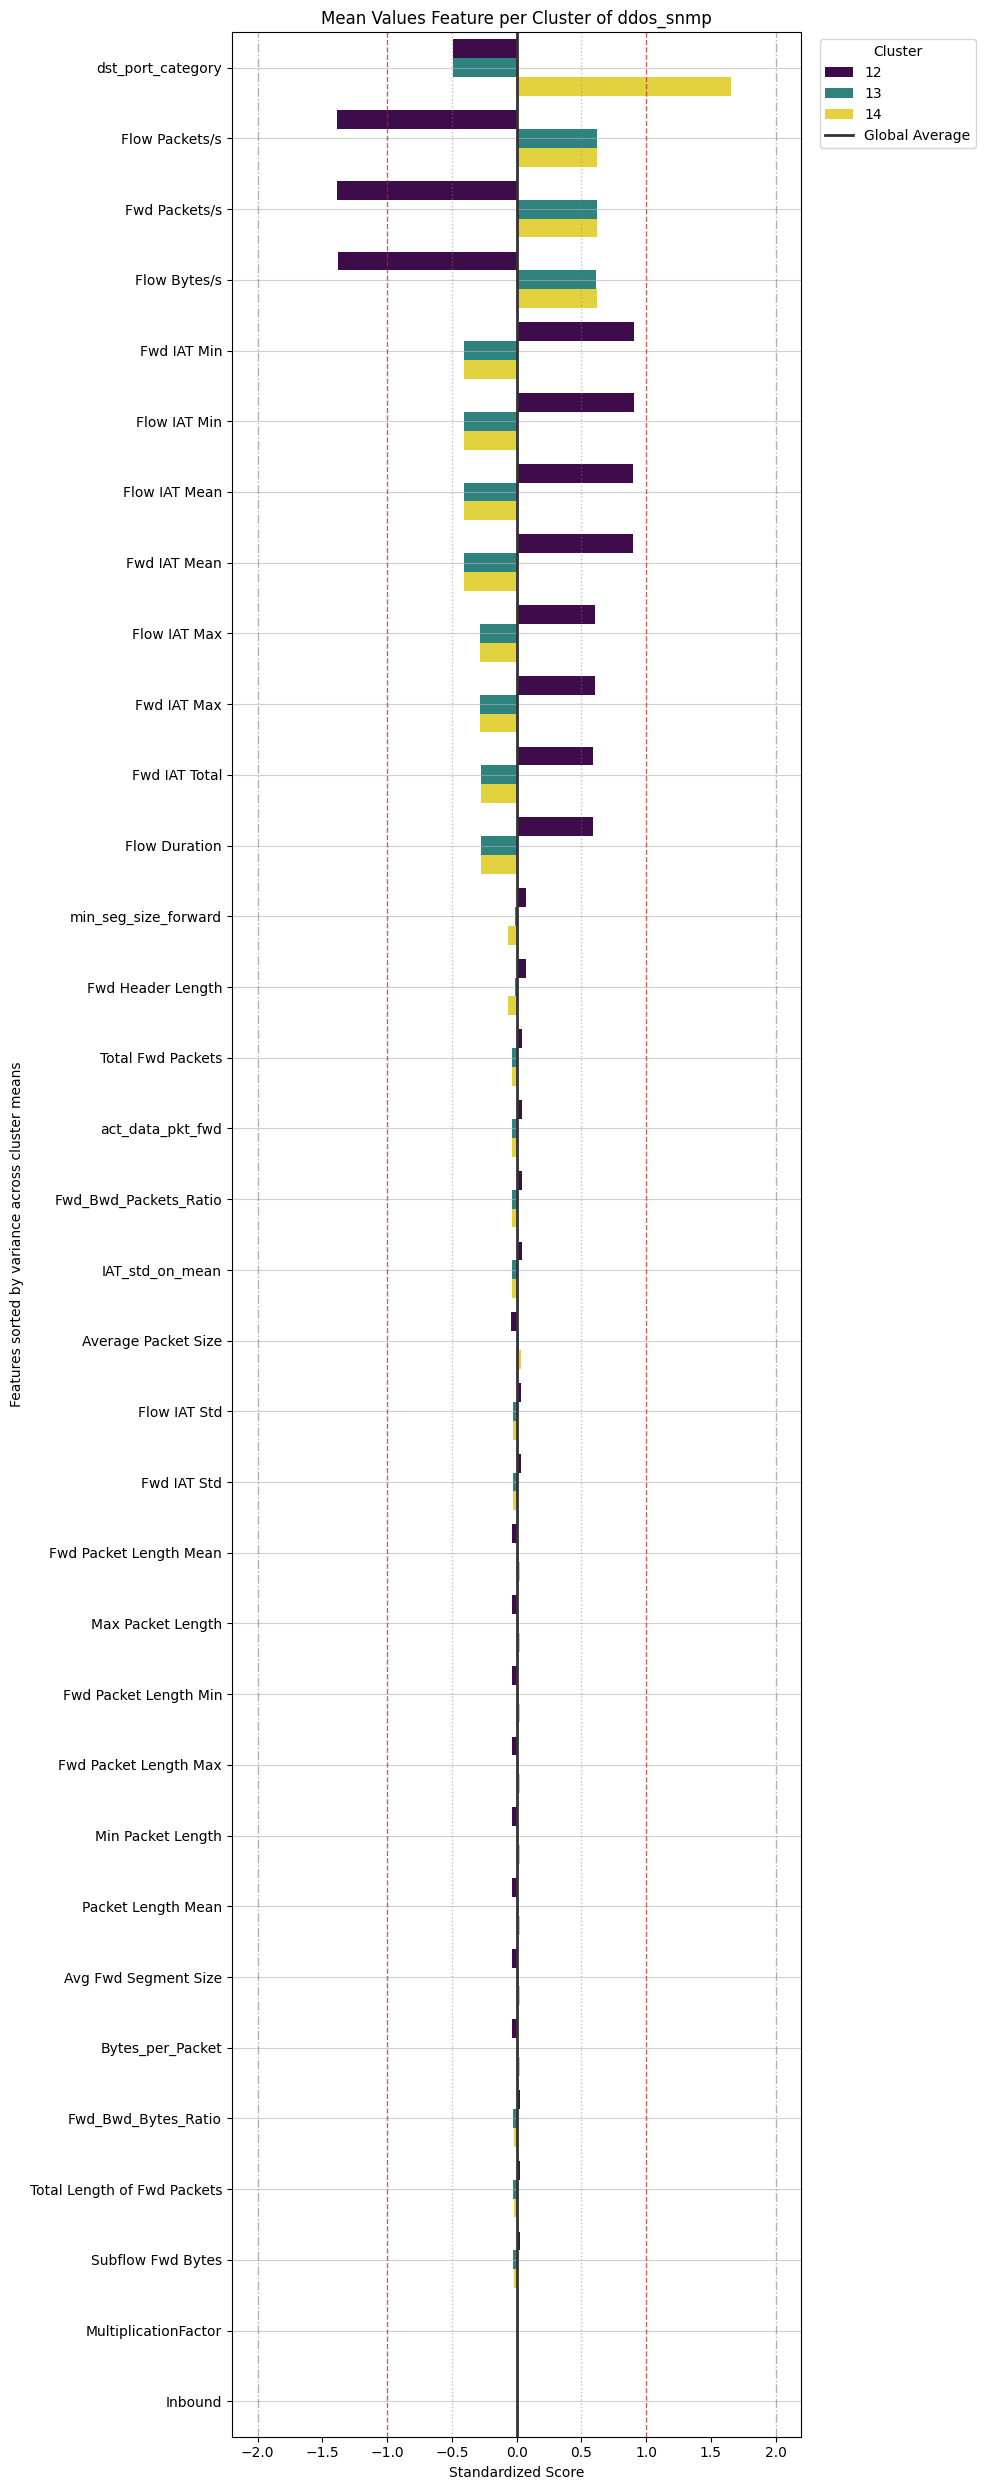

In [38]:
plotMeanFeaturesPerCluster(df_snmp_scaled, "Mean", "ddos_snmp")

### Attack Pattern Investigation – ddos_ssdp
The ddos_ssdp attack class shows distinct clustering patterns in the DBSCAN analysis, indicating that SSDP-based DDoS attacks can have multiple behavioral sub-groups. The code extracts ddos_ssdp samples, visualizes their cluster distribution, removes the dominant cluster to focus on less common patterns, and analyzes the mean standardized feature values for the remaining clusters. The resulting plots highlight which features most differentiate the sub-patterns within ddos_ssdp attacks.

In [39]:
df_ssdp , df_ssdp_scaled = getClassDf("ddos_ssdp")

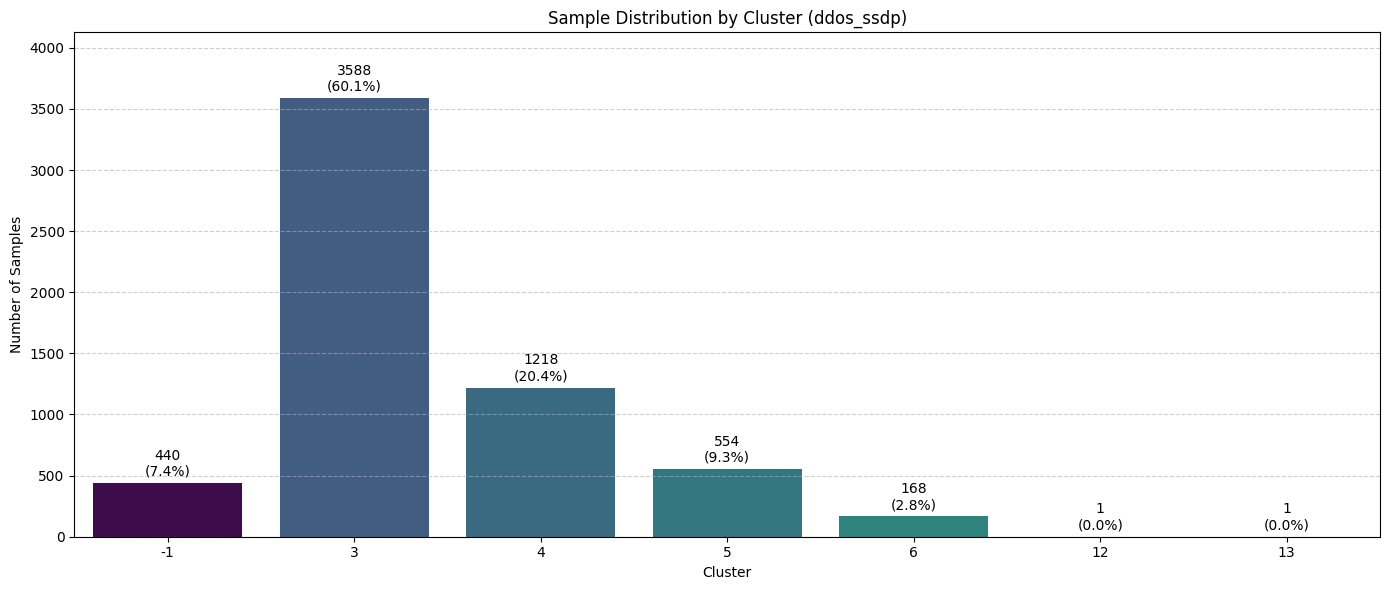

In [40]:
plotClusterSummary(df_ssdp, "ddos_ssdp")

In [41]:
toDrop = [-1, 5, 6, 12, 13]
df_ssdp = drop_clusters(df_ssdp, toDrop)
df_ssdp_scaled = drop_clusters(df_ssdp_scaled, toDrop)

In [42]:
df_ssdp.groupby("cluster").agg(["mean", "std", "median"])

Protocol             Flow Duration                      \
            mean  std median          mean          std median   
cluster                                                          
3           17.0  0.0   17.0    208.765329  9465.741414    2.0   
4           17.0  0.0   17.0      3.243842     6.406305    2.0   

        Total Fwd Packets                  Total Backward Packets  ...  \
                     mean       std median                   mean  ...   
cluster                                                            ...   
3                2.003902  0.120339    2.0           1.000000e-12  ...   
4                2.000000  0.000000    2.0           1.000000e-12  ...   

        Fwd_Bwd_Packets_Ratio Fwd_Bwd_Bytes_Ratio                              \
                       median                mean           std        median   
cluster                                                                         
3                2.000000e+12        2.914957e+15  1.957383e+14  2.944000e+15   
4                2.000000e+12        2.906289e+15  9.595957e+13  2.944000e+15   

        src_port_category             dst_port_category              
                     mean  std median              mean  std median  
cluster                                                              
3                     0.0  0.0    0.0               1.0  0.0    1.0  
4                     0.0  0.0    0.0               2.0  0.0    2.0  

[2 rows x 186 columns]

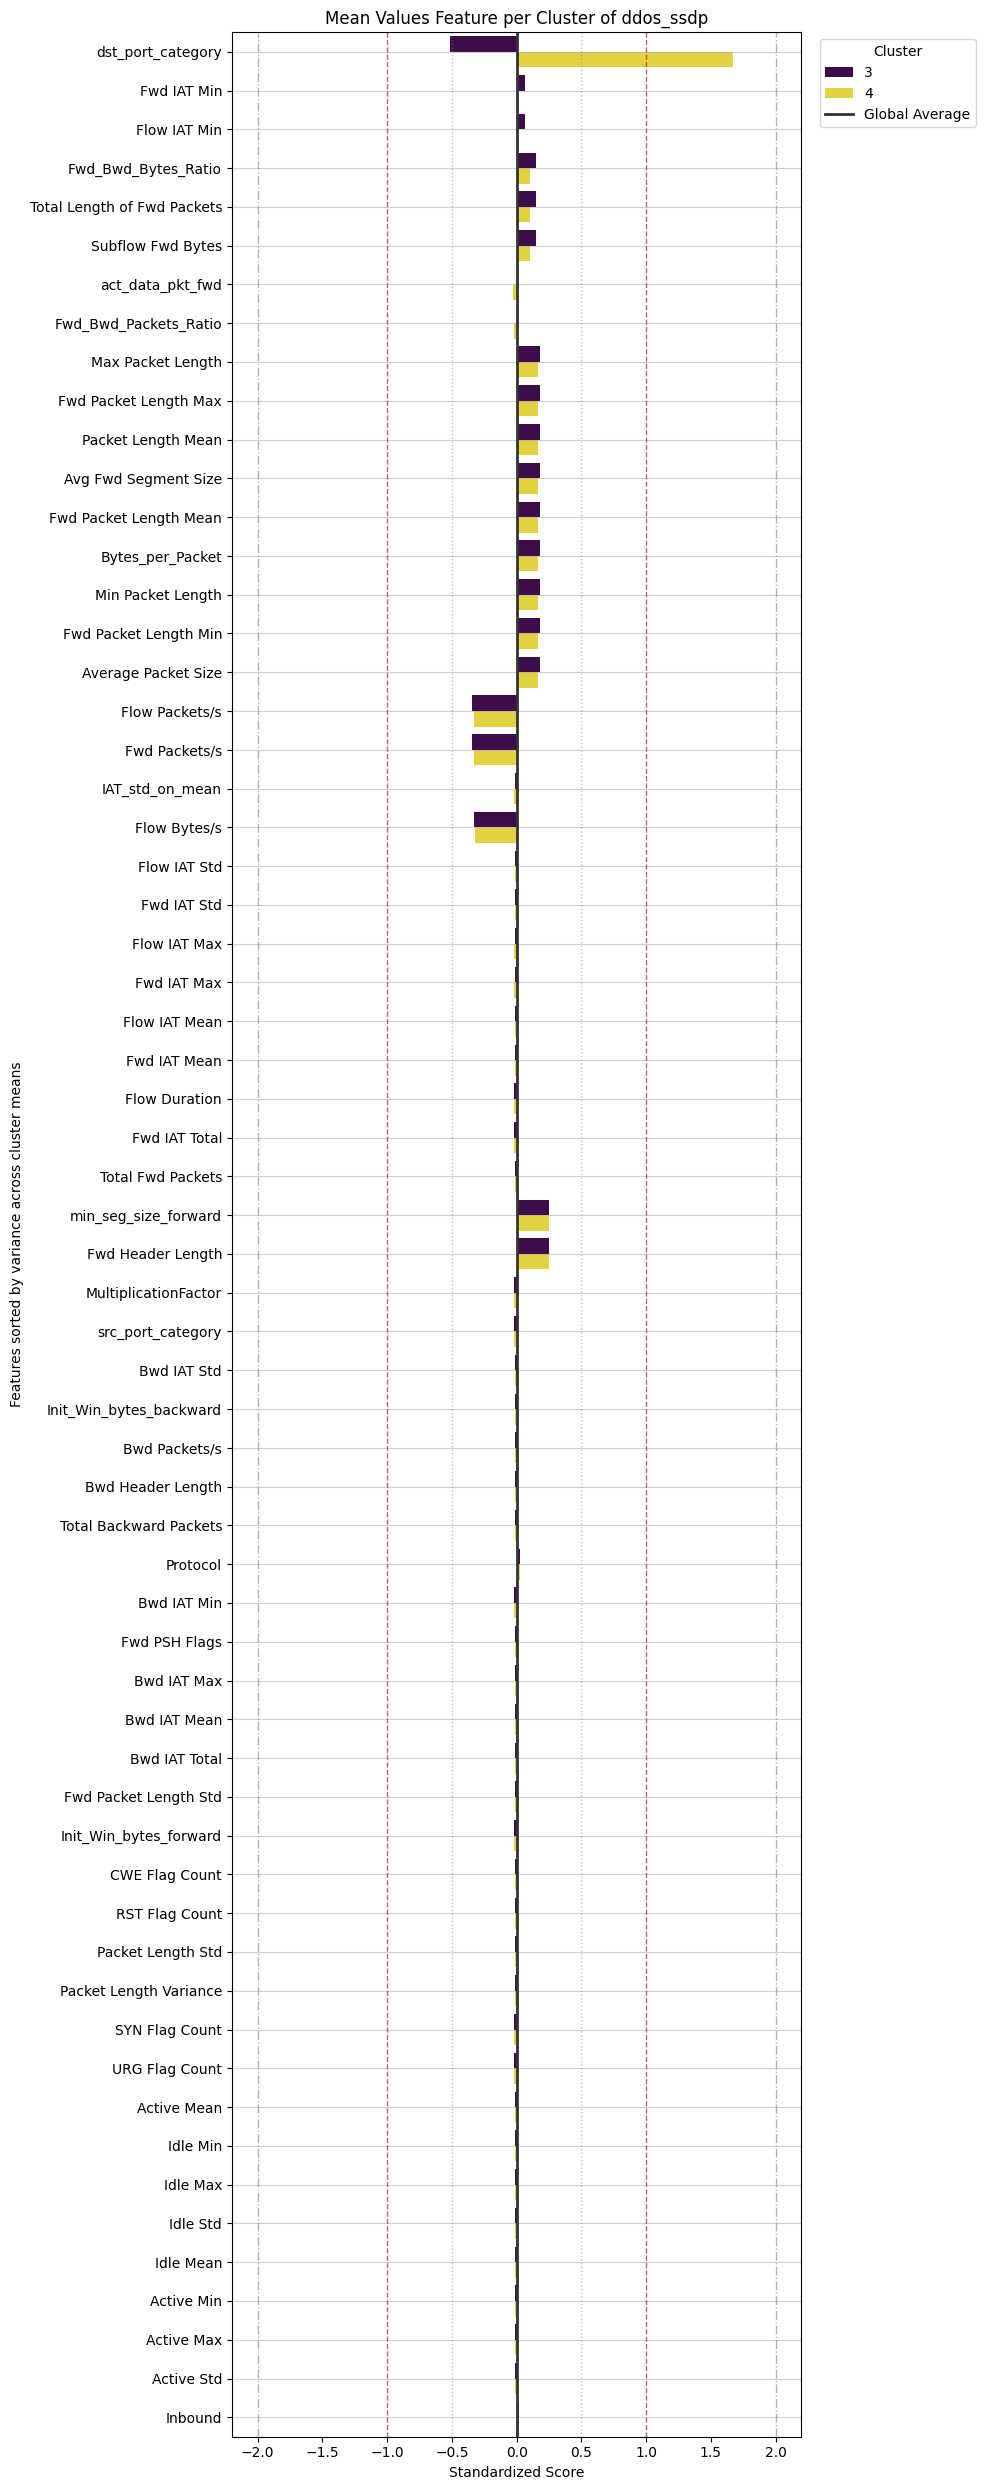

In [43]:
plotMeanFeaturesPerCluster(df_ssdp_scaled, "Mean", "ddos_ssdp")

### Attack Pattern Investigation – ddos_syn
The ddos_syn attack class is analyzed for its clustering structure using DBSCAN. The code extracts ddos_syn samples, visualizes their cluster distribution, removes the main cluster to focus on sub-patterns, and examines the mean standardized feature values for the remaining clusters. The analysis and plots reveal the key features that distinguish different behavioral patterns within SYN-based DDoS attacks.

In [44]:
df_syn , df_syn_scaled = getClassDf("ddos_syn")

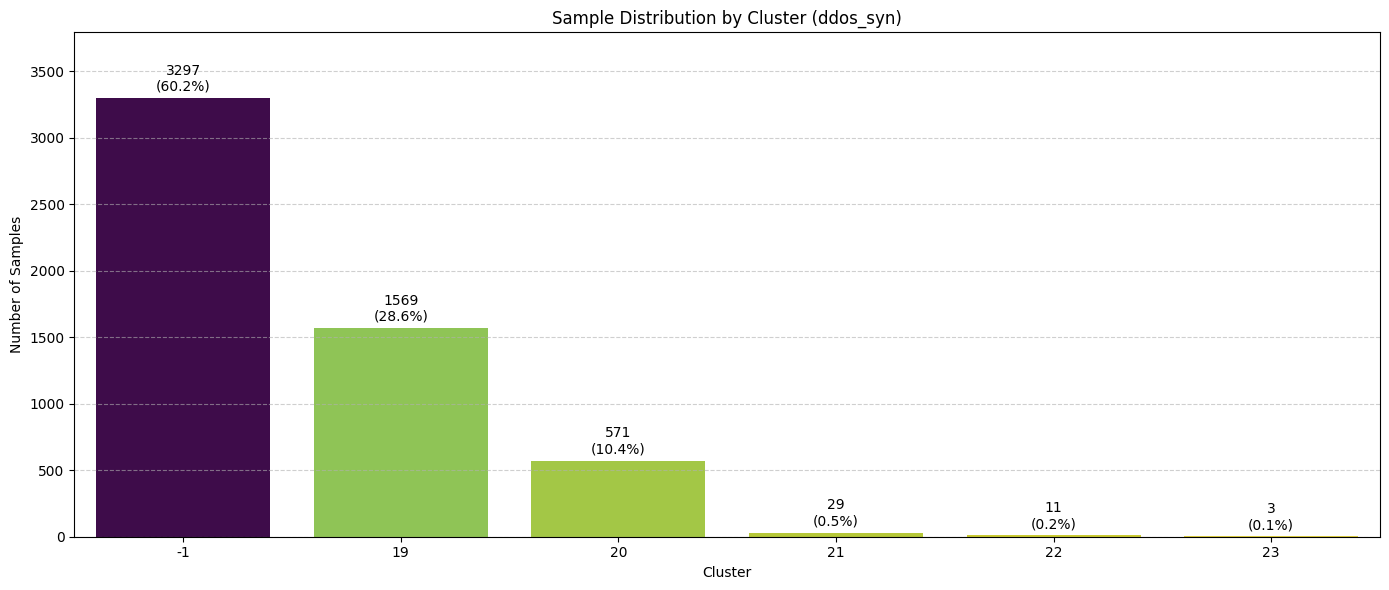

In [45]:
plotClusterSummary(df_syn, "ddos_syn")

In [46]:
toDrop = [-1, 20, 21, 22, 23]
df_syn = drop_clusters(df_syn, toDrop)
df_syn_scaled = drop_clusters(df_syn_scaled, toDrop)

In [47]:
df_syn.groupby("cluster").agg(["mean", "std", "median"])

Protocol             Flow Duration             Total Fwd Packets       \
            mean  std median          mean  std median              mean  std   
cluster                                                                         
19           6.0  0.0    6.0           1.0  0.0    1.0               2.0  0.0   

               Total Backward Packets  ... Fwd_Bwd_Packets_Ratio  \
        median                   mean  ...                median   
cluster                                ...                         
19         2.0           1.000000e-12  ...          2.000000e+12   

        Fwd_Bwd_Bytes_Ratio             src_port_category              \
                       mean  std median              mean  std median   
cluster                                                                 
19                      1.0  0.0    1.0               2.0  0.0    2.0   

        dst_port_category              
                     mean  std median  
cluster                                
19                    1.0  0.0    1.0  

[1 rows x 168 columns]

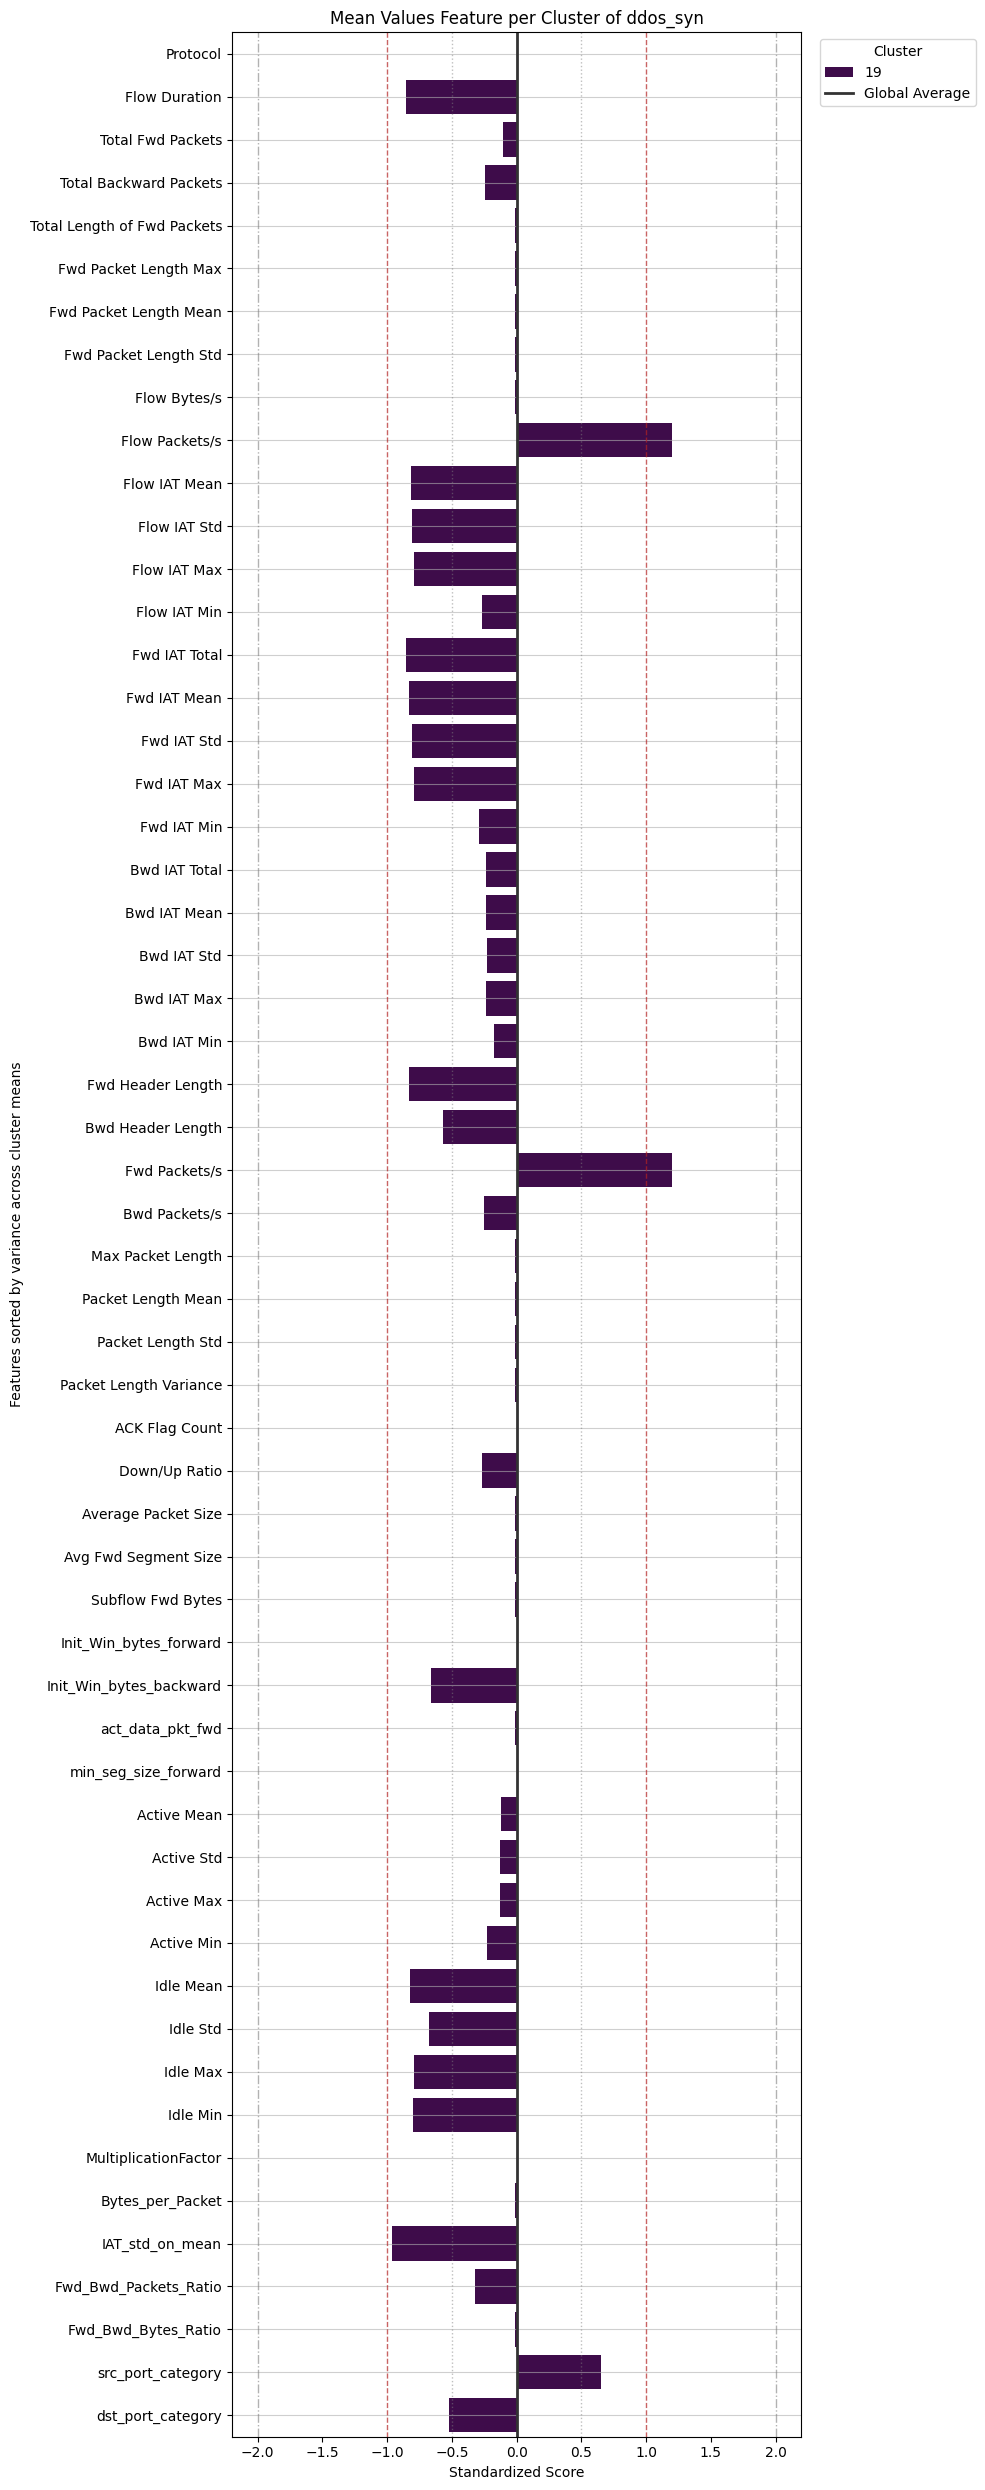

In [48]:
plotMeanFeaturesPerCluster(df_syn_scaled, "Mean", "ddos_syn")

### Attack Pattern Investigation – ddos_tftp
The ddos_tftp attack class is examined for its clustering behavior in the DBSCAN results. The code extracts ddos_tftp samples, visualizes their cluster distribution, removes the main cluster to focus on less frequent patterns, and analyzes the mean standardized feature values for the remaining clusters. The resulting plots identify the most important features that differentiate sub-patterns within TFTP-based DDoS attacks.

In [49]:
df_tftp , df_tftp_scaled = getClassDf("ddos_tftp")

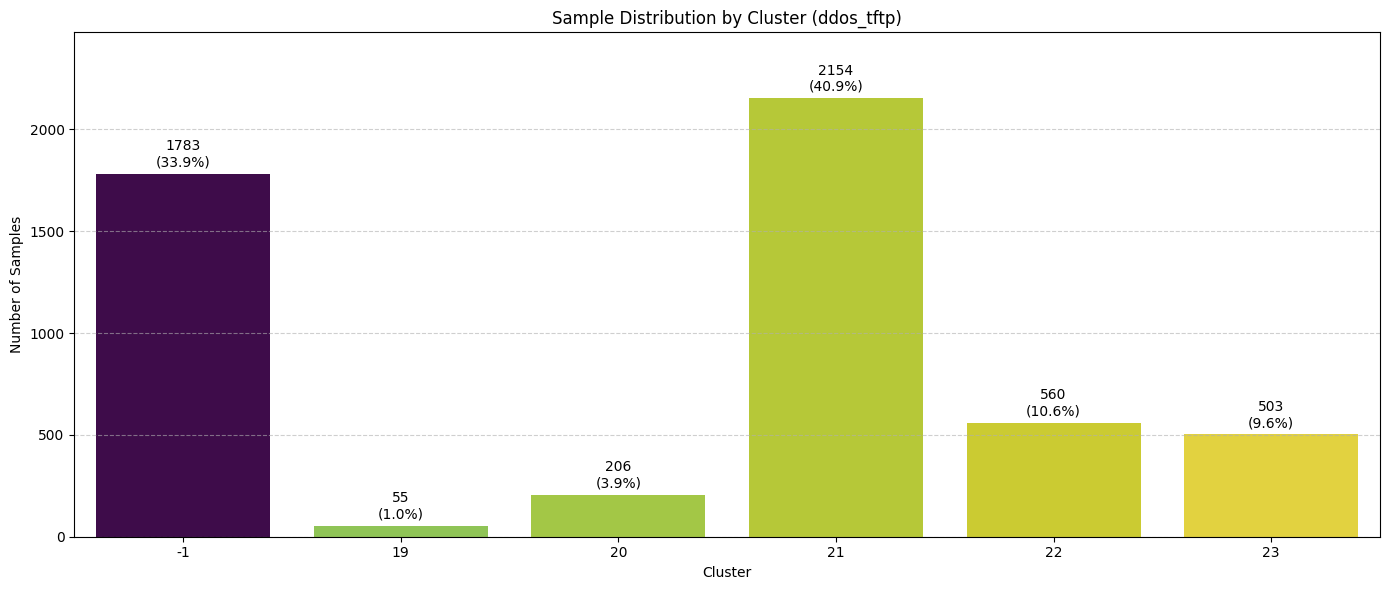

In [50]:
plotClusterSummary(df_tftp, "ddos_tftp")

In [51]:
toDrop = [-1, 19, 20, 22, 23]
df_tftp = drop_clusters(df_tftp, toDrop)
df_tftp_scaled = drop_clusters(df_tftp_scaled, toDrop)

In [52]:
df_tftp.groupby("cluster").agg(["mean", "std", "median"])

Protocol             Flow Duration             Total Fwd Packets       \
            mean  std median          mean  std median              mean  std   
cluster                                                                         
21           6.0  0.0    6.0           1.0  0.0    1.0               2.0  0.0   

               Total Backward Packets  ... Fwd_Bwd_Packets_Ratio  \
        median                   mean  ...                median   
cluster                                ...                         
21         2.0           1.000000e-12  ...          2.000000e+12   

        Fwd_Bwd_Bytes_Ratio             src_port_category              \
                       mean  std median              mean  std median   
cluster                                                                 
21                      1.0  0.0    1.0               1.0  0.0    1.0   

        dst_port_category              
                     mean  std median  
cluster                                
21                    1.0  0.0    1.0  

[1 rows x 168 columns]

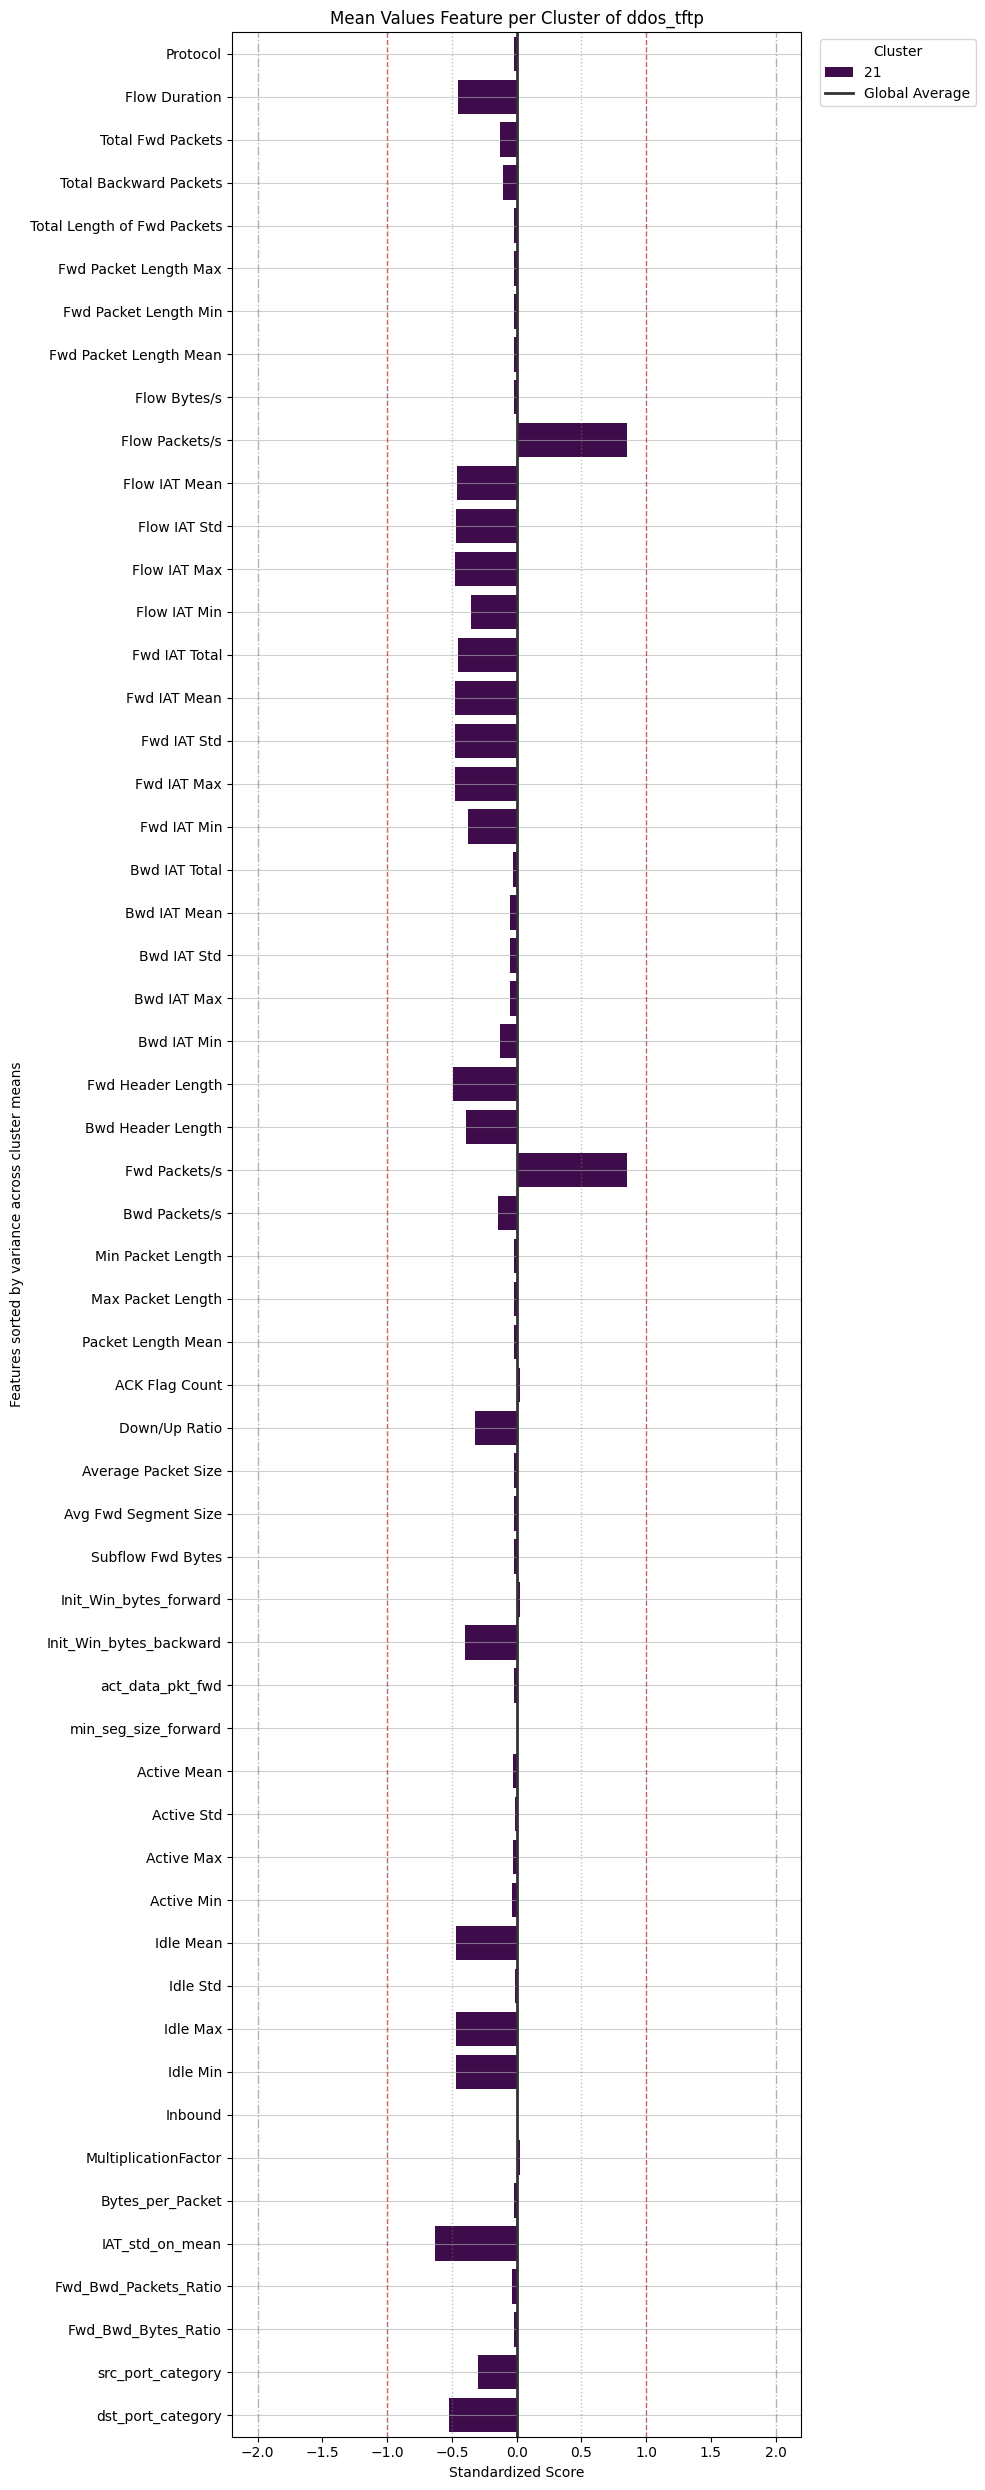

In [53]:
plotMeanFeaturesPerCluster(df_tftp_scaled, "Mean", "ddos_tftp")

### Attack Pattern Investigation – ddos_udp
The ddos_udp attack class is analyzed for its clustering structure using DBSCAN. The code extracts ddos_udp samples, visualizes their cluster distribution, removes the main cluster to focus on sub-patterns, and examines the mean standardized feature values for the remaining clusters. The analysis and plots reveal the key features that distinguish different behavioral patterns within UDP-based DDoS attacks.

In [54]:
df_udp , df_udp_scaled = getClassDf("ddos_udp")

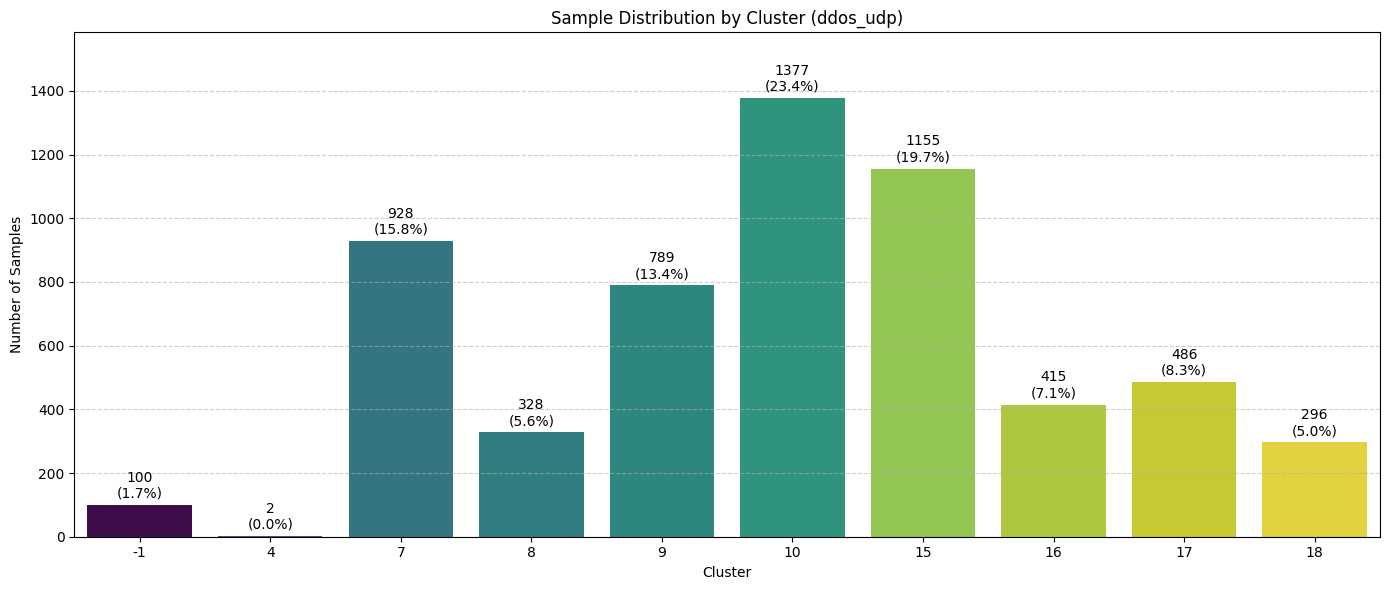

In [55]:
plotClusterSummary(df_udp, "ddos_udp")

In [56]:
toDrop = [-1, 4, 8, 16, 17, 18]
df_udp = drop_clusters(df_udp, toDrop)
df_udp_scaled = drop_clusters(df_udp_scaled, toDrop)

In [57]:
df_udp.groupby("cluster").agg(["mean", "std", "median"])

Protocol              Flow Duration                           \
            mean  std median           mean            std    median   
cluster                                                                
7           17.0  0.0   17.0       1.000000       0.000000       1.0   
9           17.0  0.0   17.0       1.000000       0.000000       1.0   
10          17.0  0.0   17.0  158453.050109  175590.265860  108541.0   
15          17.0  0.0   17.0  162202.221645  172611.508489  108684.0   

        Total Fwd Packets                  Total Backward Packets  ...  \
                     mean       std median                   mean  ...   
cluster                                                            ...   
7                2.000000  0.000000    2.0           1.000000e-12  ...   
9                2.000000  0.000000    2.0           1.000000e-12  ...   
10               4.941176  3.218343    4.0           1.000000e-12  ...   
15               4.995671  3.144550    4.0           1.000000e-12  ...   

        Fwd_Bwd_Packets_Ratio Fwd_Bwd_Bytes_Ratio                              \
                       median                mean           std        median   
cluster                                                                         
7                2.000000e+12        7.720280e+14  2.145001e+13  7.660000e+14   
9                2.000000e+12        7.724183e+14  2.208434e+13  7.660000e+14   
10               4.000000e+12        1.761126e+15  1.163736e+15  1.438000e+15   
15               4.000000e+12        1.778097e+15  1.139682e+15  1.438000e+15   

        src_port_category             dst_port_category              
                     mean  std median              mean  std median  
cluster                                                              
7                     1.0  0.0    1.0               1.0  0.0    1.0  
9                     2.0  0.0    2.0               1.0  0.0    1.0  
10                    1.0  0.0    1.0               1.0  0.0    1.0  
15                    2.0  0.0    2.0               1.0  0.0    1.0  

[4 rows x 159 columns]

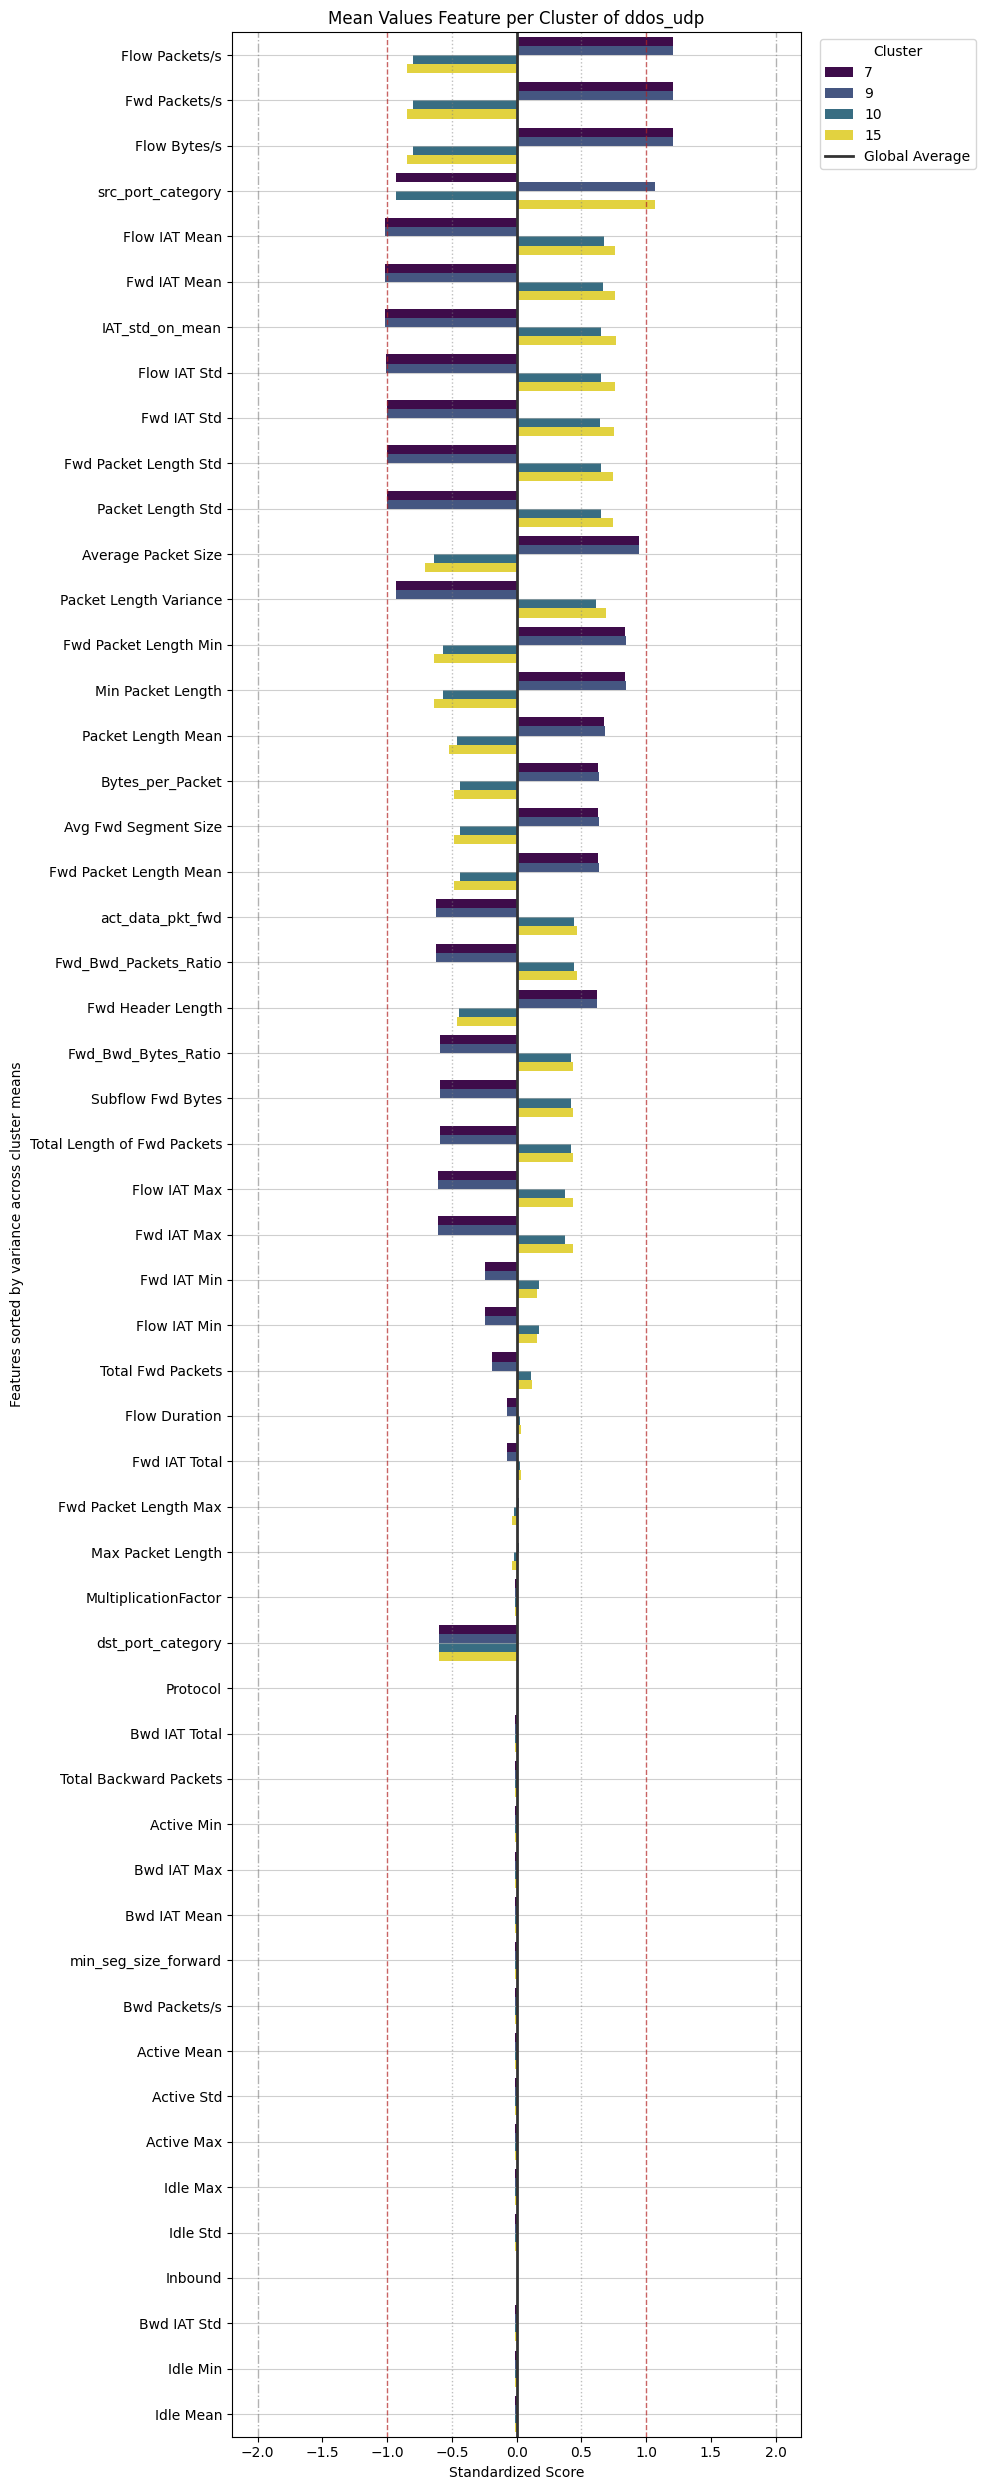

In [58]:
plotMeanFeaturesPerCluster(df_udp_scaled, "Mean", "ddos_udp")

### Attack Pattern Investigation – ddos_udplag
The ddos_udplag attack class is analyzed for its clustering structure using DBSCAN. The code extracts ddos_udplag samples, visualizes their cluster distribution, removes the main cluster to focus on less common sub-patterns, and examines the mean standardized feature values for the remaining clusters. The analysis and plots highlight the key features that differentiate behavioral patterns within UDP-lag-based DDoS attacks.

In [59]:
df_udp_lag , df_udp_lag_scaled = getClassDf("ddos_udp_lag")

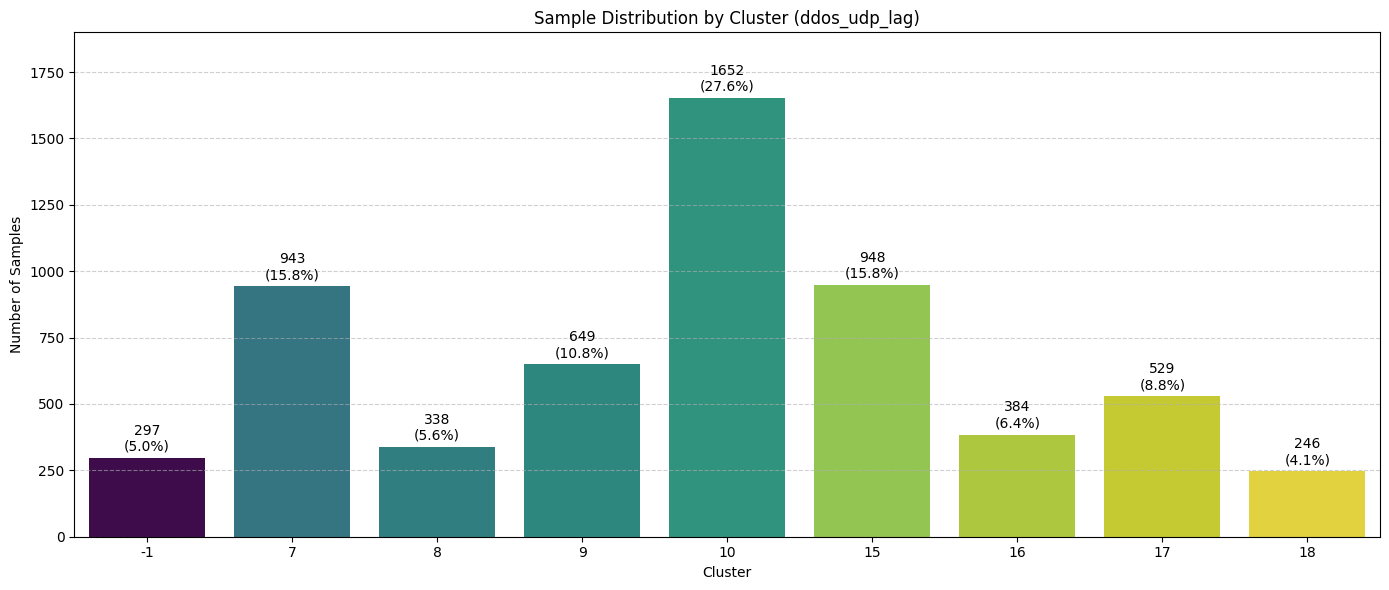

In [60]:
plotClusterSummary(df_udp_lag, "ddos_udp_lag")

In [61]:
toDrop = [-1, 8, 9, 16, 17, 18]
df_udp_lag = drop_clusters(df_udp_lag, toDrop)
df_udp_lag_scaled = drop_clusters(df_udp_lag_scaled, toDrop)

In [62]:
df_udp_lag.groupby("cluster").agg(["mean", "std", "median"])

Flow Duration                          Total Fwd Packets            \
                  mean            std    median              mean       std   
cluster                                                                       
7             1.000000       0.000000       1.0          2.000000  0.000000   
10       139398.401332  163044.549052  108003.0          4.604116  3.023138   
15       146024.974684  148672.726000  108564.0          4.725738  2.741348   

               Total Length of Fwd Packets                       \
        median                        mean          std  median   
cluster                                                           
7          2.0                  772.990456    26.990895   766.0   
10         4.0                 1646.750605  1082.341195  1438.0   
15         4.0                 1683.664557   986.116058  1438.0   

        Fwd Packet Length Max  ... Fwd_Bwd_Packets_Ratio Fwd_Bwd_Bytes_Ratio  \
                         mean  ...                median                mean   
cluster                        ...                                             
7                  386.495228  ...          2.000000e+12        7.729905e+14   
10                 385.373487  ...          4.000000e+12        1.646751e+15   
15                 385.181435  ...          4.000000e+12        1.683665e+15   

                                    src_port_category              \
                  std        median              mean  std median   
cluster                                                             
7        2.699089e+13  7.660000e+14               1.0  0.0    1.0   
10       1.082341e+15  1.438000e+15               1.0  0.0    1.0   
15       9.861161e+14  1.438000e+15               2.0  0.0    2.0   

        dst_port_category              
                     mean  std median  
cluster                                
7                     1.0  0.0    1.0  
10                    1.0  0.0    1.0  
15                    1.0  0.0    1.0  

[3 rows x 111 columns]

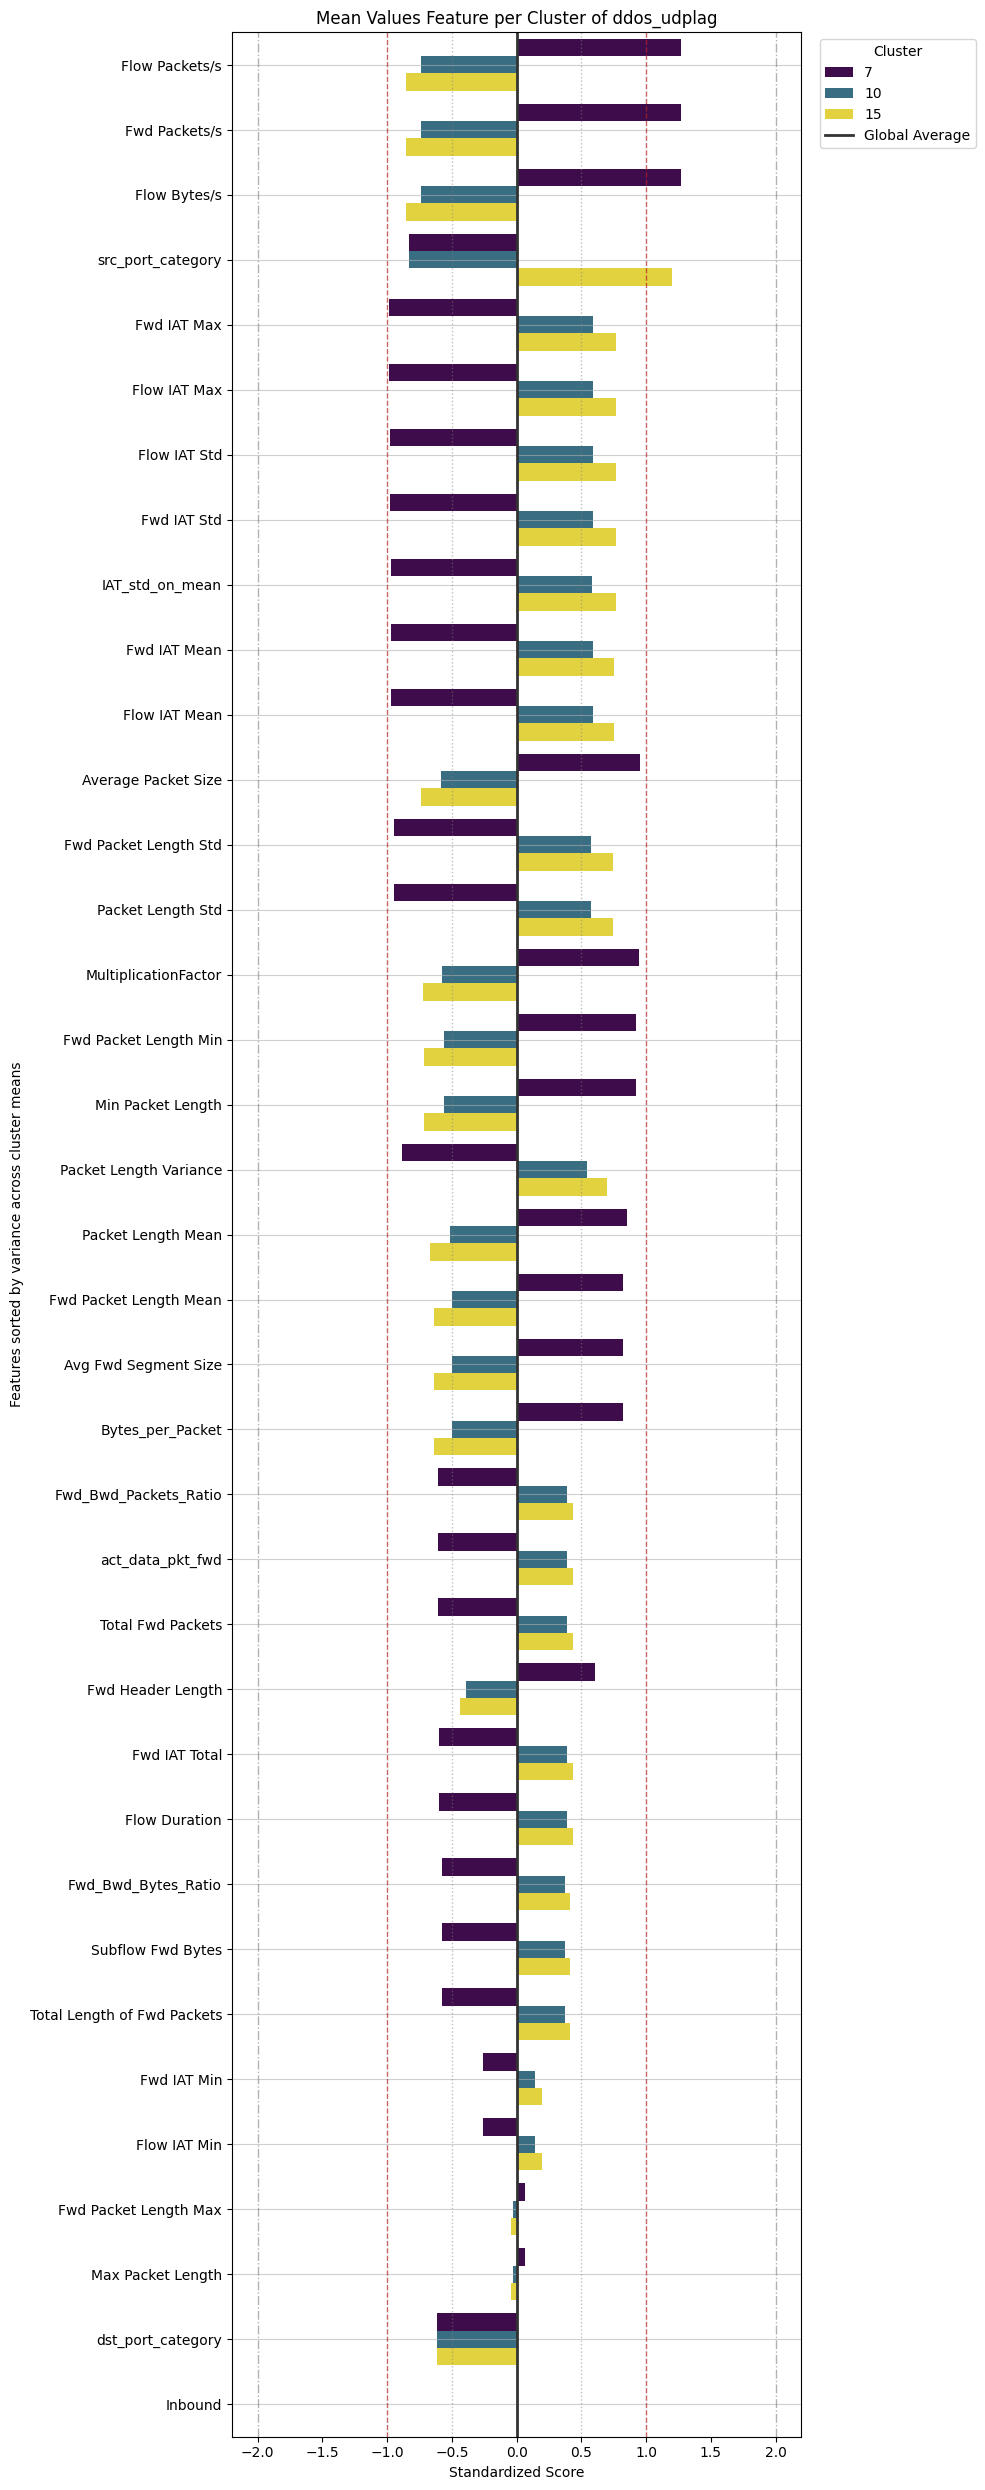

In [63]:
plotMeanFeaturesPerCluster(df_udp_lag_scaled, "Mean", "ddos_udplag")

### b)  Which attacks are more similar? According to which feature? Can you explain why according to their definition or attack manner? 

Yes, the clustering clearly reveals that **attacks belonging to different DDoS class show same behavioral patterns**, as they are mapped to **same clusters**.

1. To identify which attacks exhibit the most similar behaviors, we examined the standardized feature distributions of different attack labels co-existing within Clusters, ranking features according to their inter-label variance within the cluster.
2. Features that showed the same values across all clusters, were excluded from the analysis, as they do not contribute to the characterization of the different sub-attack groups.
3. Labels representing less than ~5% of the samples were excluded from the analysis, as they likely correspond to noise, outliers, or rare behaviors that do not significantly contribute to the dominant attack patterns

In [64]:
def getClusterDf(cluster_id):
    df_clustered = df_pd.copy()

    df_cluster = df_clustered[df_clustered["cluster"] == cluster_id].copy().reset_index(drop=True)
    df_cluster = df_cluster.drop(columns="cluster")
    
    # Save label column before filtering
    label_col = df_cluster["label"].copy()
    
    # Filter features but exclude label from the filter
    features = df_cluster.drop(columns="label")
    features = features.loc[:, features.nunique() > 1]

    df_cluster_scaled = pd.DataFrame(StandardScaler().fit_transform(features), columns=features.columns)
    df_cluster_scaled['label'] = label_col
    
    # For df_cluster, keep only the filtered features + label
    df_cluster = features.copy()
    df_cluster['label'] = label_col
    
    return df_cluster, df_cluster_scaled

In [65]:
def plotLabelSummary(df, cluster):
    counts = df["label"].value_counts().sort_index()
    percentages = (df["label"].value_counts(normalize=True).sort_index() * 100)

    plt.figure(figsize=(10, 6))

    ax = sns.barplot(x=counts.index, y=counts.values, palette='viridis', hue=counts.index, legend=False)

    labels = []
    for i in range(len(counts)):
        c = counts.values[i]
        p = percentages.values[i]
        testo = f'{int(c)}\n({p:.1f}%)'
        labels.append(testo)
        
    for i, container in enumerate(ax.containers):
        ax.bar_label(container, labels=[labels[i]], padding=3)

    plt.title(f"Sample Distribution by Label (cluster {cluster})")
    plt.xlabel("Cluster")
    plt.ylabel("Number of Samples")
    plt.ylim(0, max(counts.values) * 1.15) 
    plt.grid(axis='y', linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.show()

In [66]:
def drop_Labels(df, toDrop):
    for id in toDrop:
        df = df[df["label"] != id].reset_index(drop=True)
    return df

In [67]:
def plotMeanFeaturesPerLabel(df_s, mesure, cluster_id):
    if mesure == "Mean":
        df_mesure = df_s.groupby("label").mean().reset_index()
        sorted_features = df_s.groupby("label").mean().var().sort_values(ascending=False).index
    elif mesure == "Median":
        df_mesure = df_s.groupby("label").median().reset_index()
        sorted_features = df_s.groupby("label").median().var().sort_values(ascending=False).index
    else:
        print("Mesure invalid")
        return
    
    df_melted = df_mesure.melt(id_vars="label", var_name="Feature", value_name="Standardized Value")

    plt.figure(figsize=(15, 25)) 

    sns.barplot(data=df_melted, x="Standardized Value", y="Feature", hue="label", palette="viridis", order=sorted_features)

    plt.axvline(0, color='#333333', linewidth=2, label='Global Average') 
    plt.axvline(x=1, color='firebrick', linestyle='--', linewidth=1, alpha=0.7)
    plt.axvline(x=-1, color='firebrick', linestyle='--', linewidth=1, alpha=0.7)
    plt.axvline(x=0.5, color='gray', linestyle=':', linewidth=1, alpha=0.5)
    plt.axvline(x=-0.5, color='gray', linestyle=':', linewidth=1, alpha=0.5)
    plt.axvline(x=2, color='gray', linestyle='-.', linewidth=1, alpha=0.6)
    plt.axvline(x=-2, color='gray', linestyle='-.', linewidth=1, alpha=0.6)

    plt.title(f"{mesure} Values Feature per Label of cluster {cluster_id}")
    plt.xlabel("Standardized Score")
    plt.ylabel("Features")
    plt.legend(title="Label", bbox_to_anchor=(1.02, 1), loc='upper left')

    plt.grid(axis='y', alpha=0.6)
    plt.tight_layout()
    plt.show()

### Attack Pattern Investigation – Cluster 1
Cluster 1 represents a density-based region identified by DBSCAN that contains a specific subset of DDoS attack traffic. The code extracts all samples assigned to cluster 1, visualizes the distribution of attack labels within the cluster, removes less relevant labels, and analyzes the mean standardized feature values for each remaining attack type. The resulting plots reveal which attack types co-exist in this cluster and highlight the shared behavioral characteristics that define this group.

In [68]:
df_cluster_5 , df_cluster_5_scaled = getClusterDf(5)

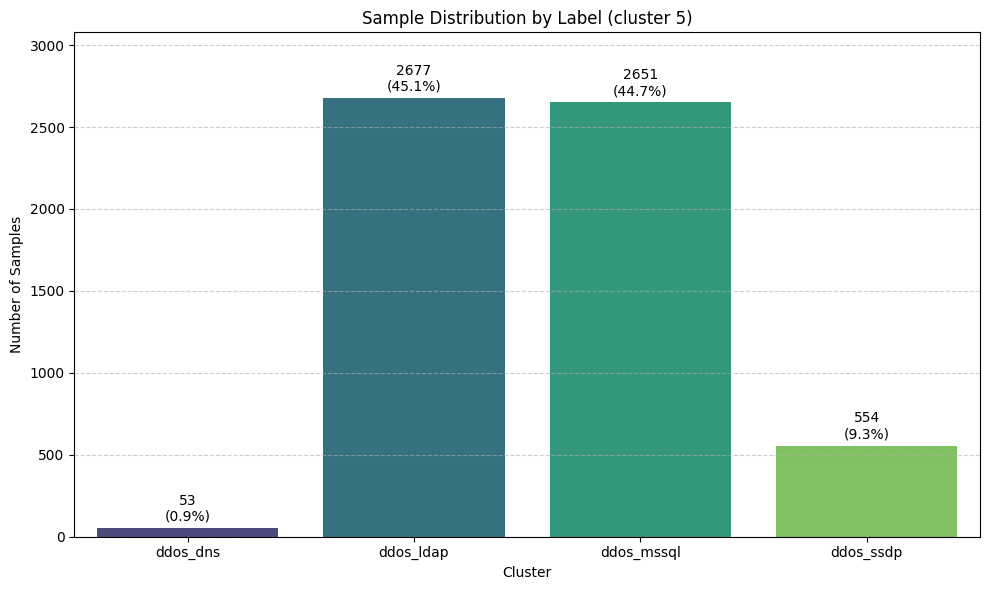

In [69]:
plotLabelSummary(df_cluster_5,5)

In [70]:
toDrop = ["ddos_benign", "ddos_dns", "ddos_ssdp"]
df_cluster_5 = drop_Labels(df_cluster_5, toDrop)
df_cluster_5_scaled = drop_Labels(df_cluster_5_scaled, toDrop)

In [71]:
df_cluster_5.groupby("label").agg(["mean", "std", "median"])

Total Length of Fwd Packets                     \
                                  mean        std  median   
label                                                       
ddos_ldap                  2931.125887  59.726390  2944.0   
ddos_mssql                 2930.064127  68.771476  2944.0   

           Fwd Packet Length Max                    Fwd Packet Length Min  \
                            mean        std  median                  mean   
label                                                                       
ddos_ldap            1465.562944  29.863195  1472.0           1465.562944   
ddos_mssql           1465.032063  34.385738  1472.0           1465.032063   

                              Fwd Packet Length Mean  ...  \
                  std  median                   mean  ...   
label                                                 ...   
ddos_ldap   29.863195  1472.0            1465.562944  ...   
ddos_mssql  34.385738  1472.0            1465.032063  ...   

           MultiplicationFactor Bytes_per_Packet                     \
                         median             mean        std  median   
label                                                                 
ddos_ldap          3.396739e-16      1465.562944  29.863195  1472.0   
ddos_mssql         3.396739e-16      1465.032063  34.385738  1472.0   

           Fwd_Bwd_Bytes_Ratio                              hour              
                          mean           std        median  mean  std median  
label                                                                         
ddos_ldap         2.931126e+15  5.972639e+13  2.944000e+15  11.0  0.0   11.0  
ddos_mssql        2.930064e+15  6.877148e+13  2.944000e+15  11.0  0.0   11.0  

[2 rows x 51 columns]

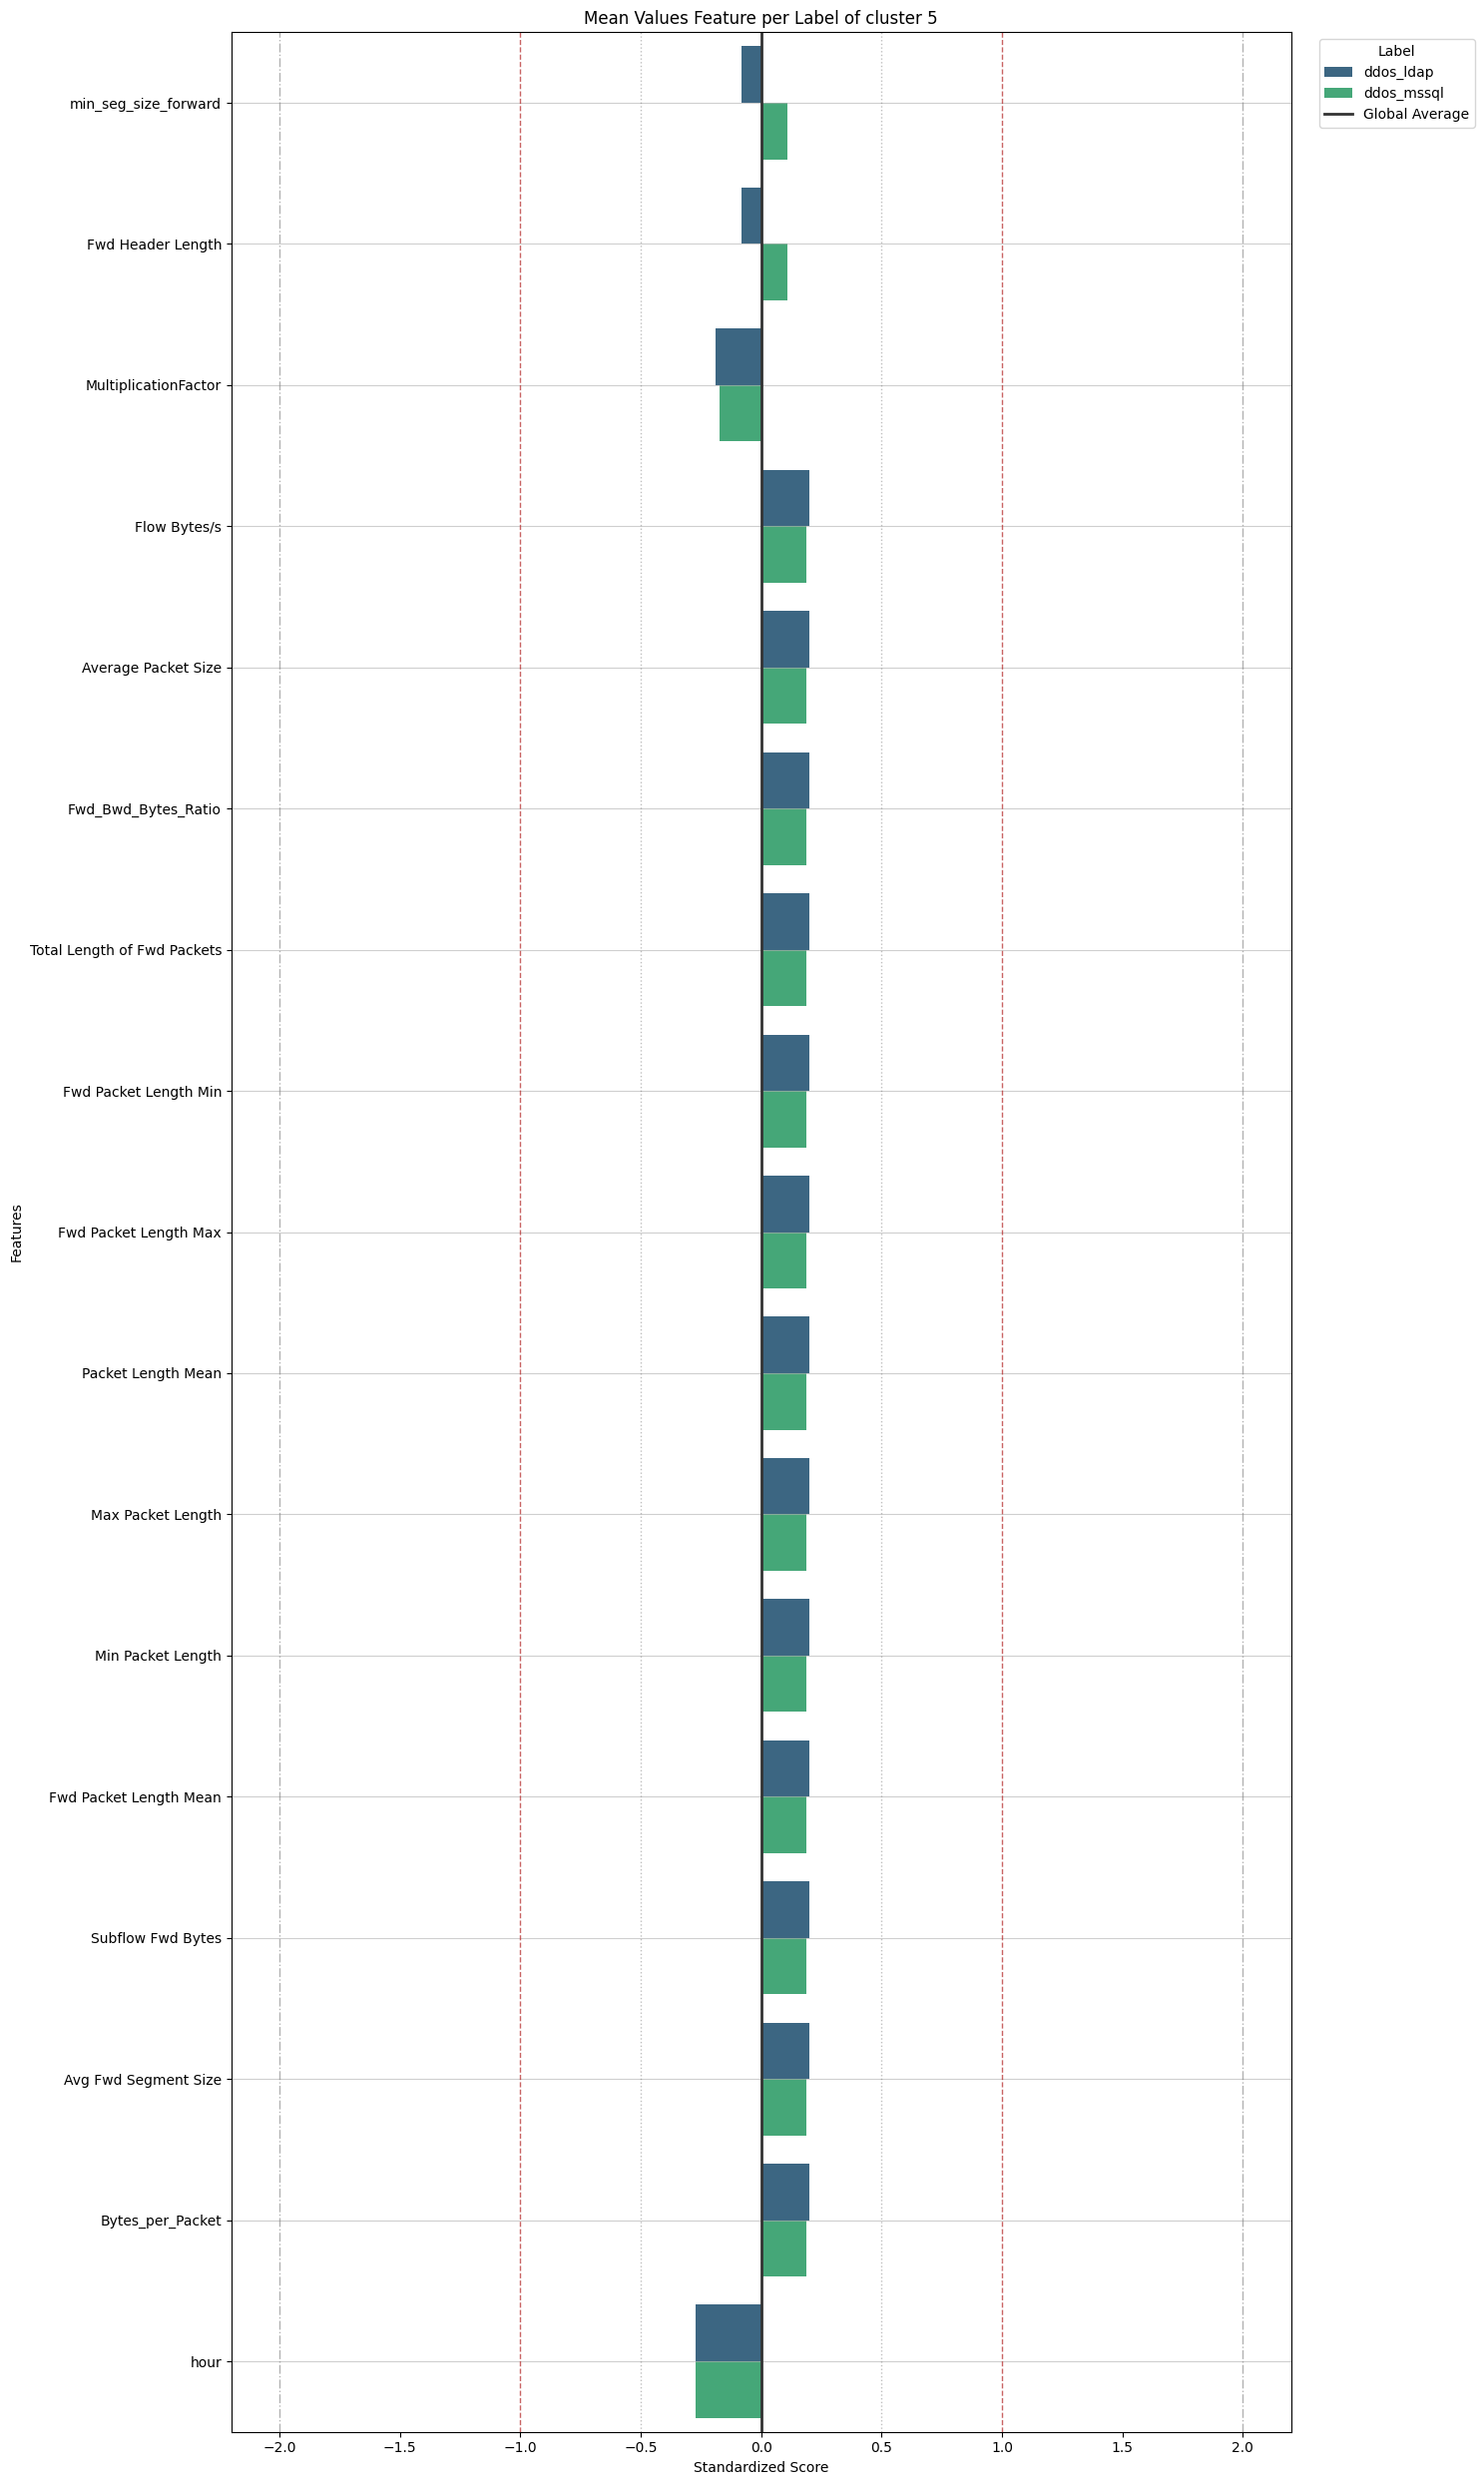

In [72]:
plotMeanFeaturesPerLabel(df_cluster_5_scaled, "Mean", 5)

### Attack Pattern Investigation – Cluster 2
Cluster 2 demonstrates how DBSCAN groups together attack types with similar network behavior patterns. The code extracts all samples assigned to cluster 2, visualizes the distribution of attack labels, removes less relevant labels, and analyzes the mean standardized feature values for each remaining attack type. The analysis and plots identify which attacks exhibit comparable feature signatures and the network metrics that create these associations.

In [73]:
df_cluster_7 , df_cluster_7_scaled = getClusterDf(7)

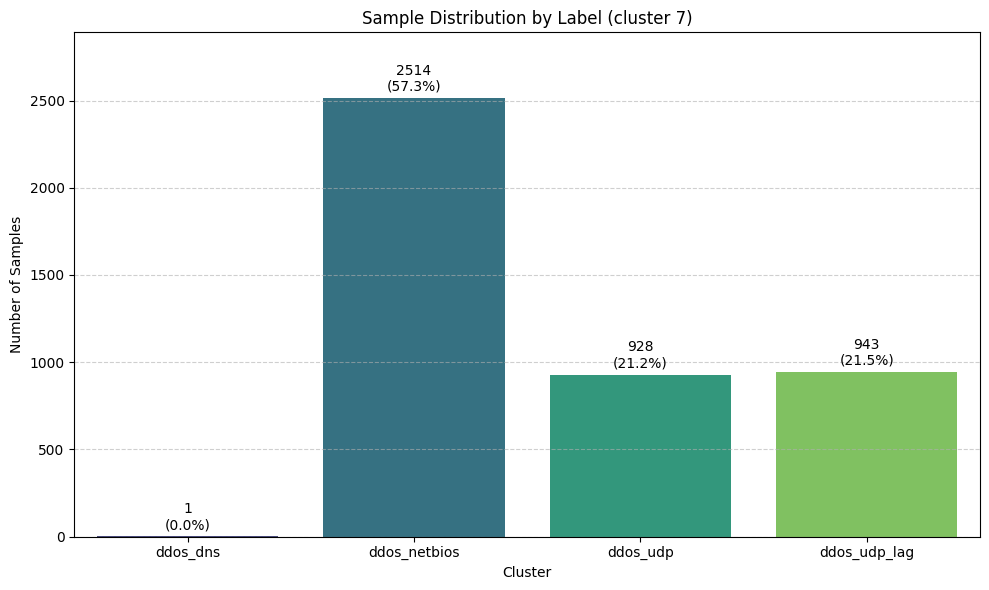

In [74]:
plotLabelSummary(df_cluster_7, 7)

In [75]:
toDrop = ["ddos_benign", "ddos_dns"]
df_cluster_7 = drop_Labels(df_cluster_7, toDrop)
df_cluster_7_scaled = drop_Labels(df_cluster_7_scaled, toDrop)

In [76]:
df_cluster_7.groupby("label").agg(["mean", "std", "median"])

Total Length of Fwd Packets                     \
                                    mean         std median   
label                                                         
ddos_netbios                 1053.657120  258.333984  956.0   
ddos_udp                      772.028017   21.450006  766.0   
ddos_udp_lag                  772.990456   26.990895  766.0   

             Fwd Packet Length Max                    Fwd Packet Length Min  \
                              mean         std median                  mean   
label                                                                         
ddos_netbios            526.828560  129.166992  478.0            526.828560   
ddos_udp                386.014009   10.725003  383.0            386.014009   
ddos_udp_lag            386.495228   13.495447  383.0            386.495228   

                                Fwd Packet Length Mean  ...  \
                     std median                   mean  ...   
label                                                   ...   
ddos_netbios  129.166992  478.0             526.828560  ...   
ddos_udp       10.725003  383.0             386.014009  ...   
ddos_udp_lag   13.495447  383.0             386.495228  ...   

             MultiplicationFactor Bytes_per_Packet                     \
                           median             mean         std median   
label                                                                   
ddos_netbios         1.046025e-15       526.828560  129.166992  478.0   
ddos_udp             1.305483e-15       386.014009   10.725003  383.0   
ddos_udp_lag         1.305483e-15       386.495228   13.495447  383.0   

             Fwd_Bwd_Bytes_Ratio                              hour              
                            mean           std        median  mean  std median  
label                                                                           
ddos_netbios        1.053657e+15  2.583340e+14  9.560000e+14  11.0  0.0   11.0  
ddos_udp            7.720280e+14  2.145001e+13  7.660000e+14  12.0  0.0   12.0  
ddos_udp_lag        7.729905e+14  2.699089e+13  7.660000e+14  13.0  0.0   13.0  

[3 rows x 51 columns]

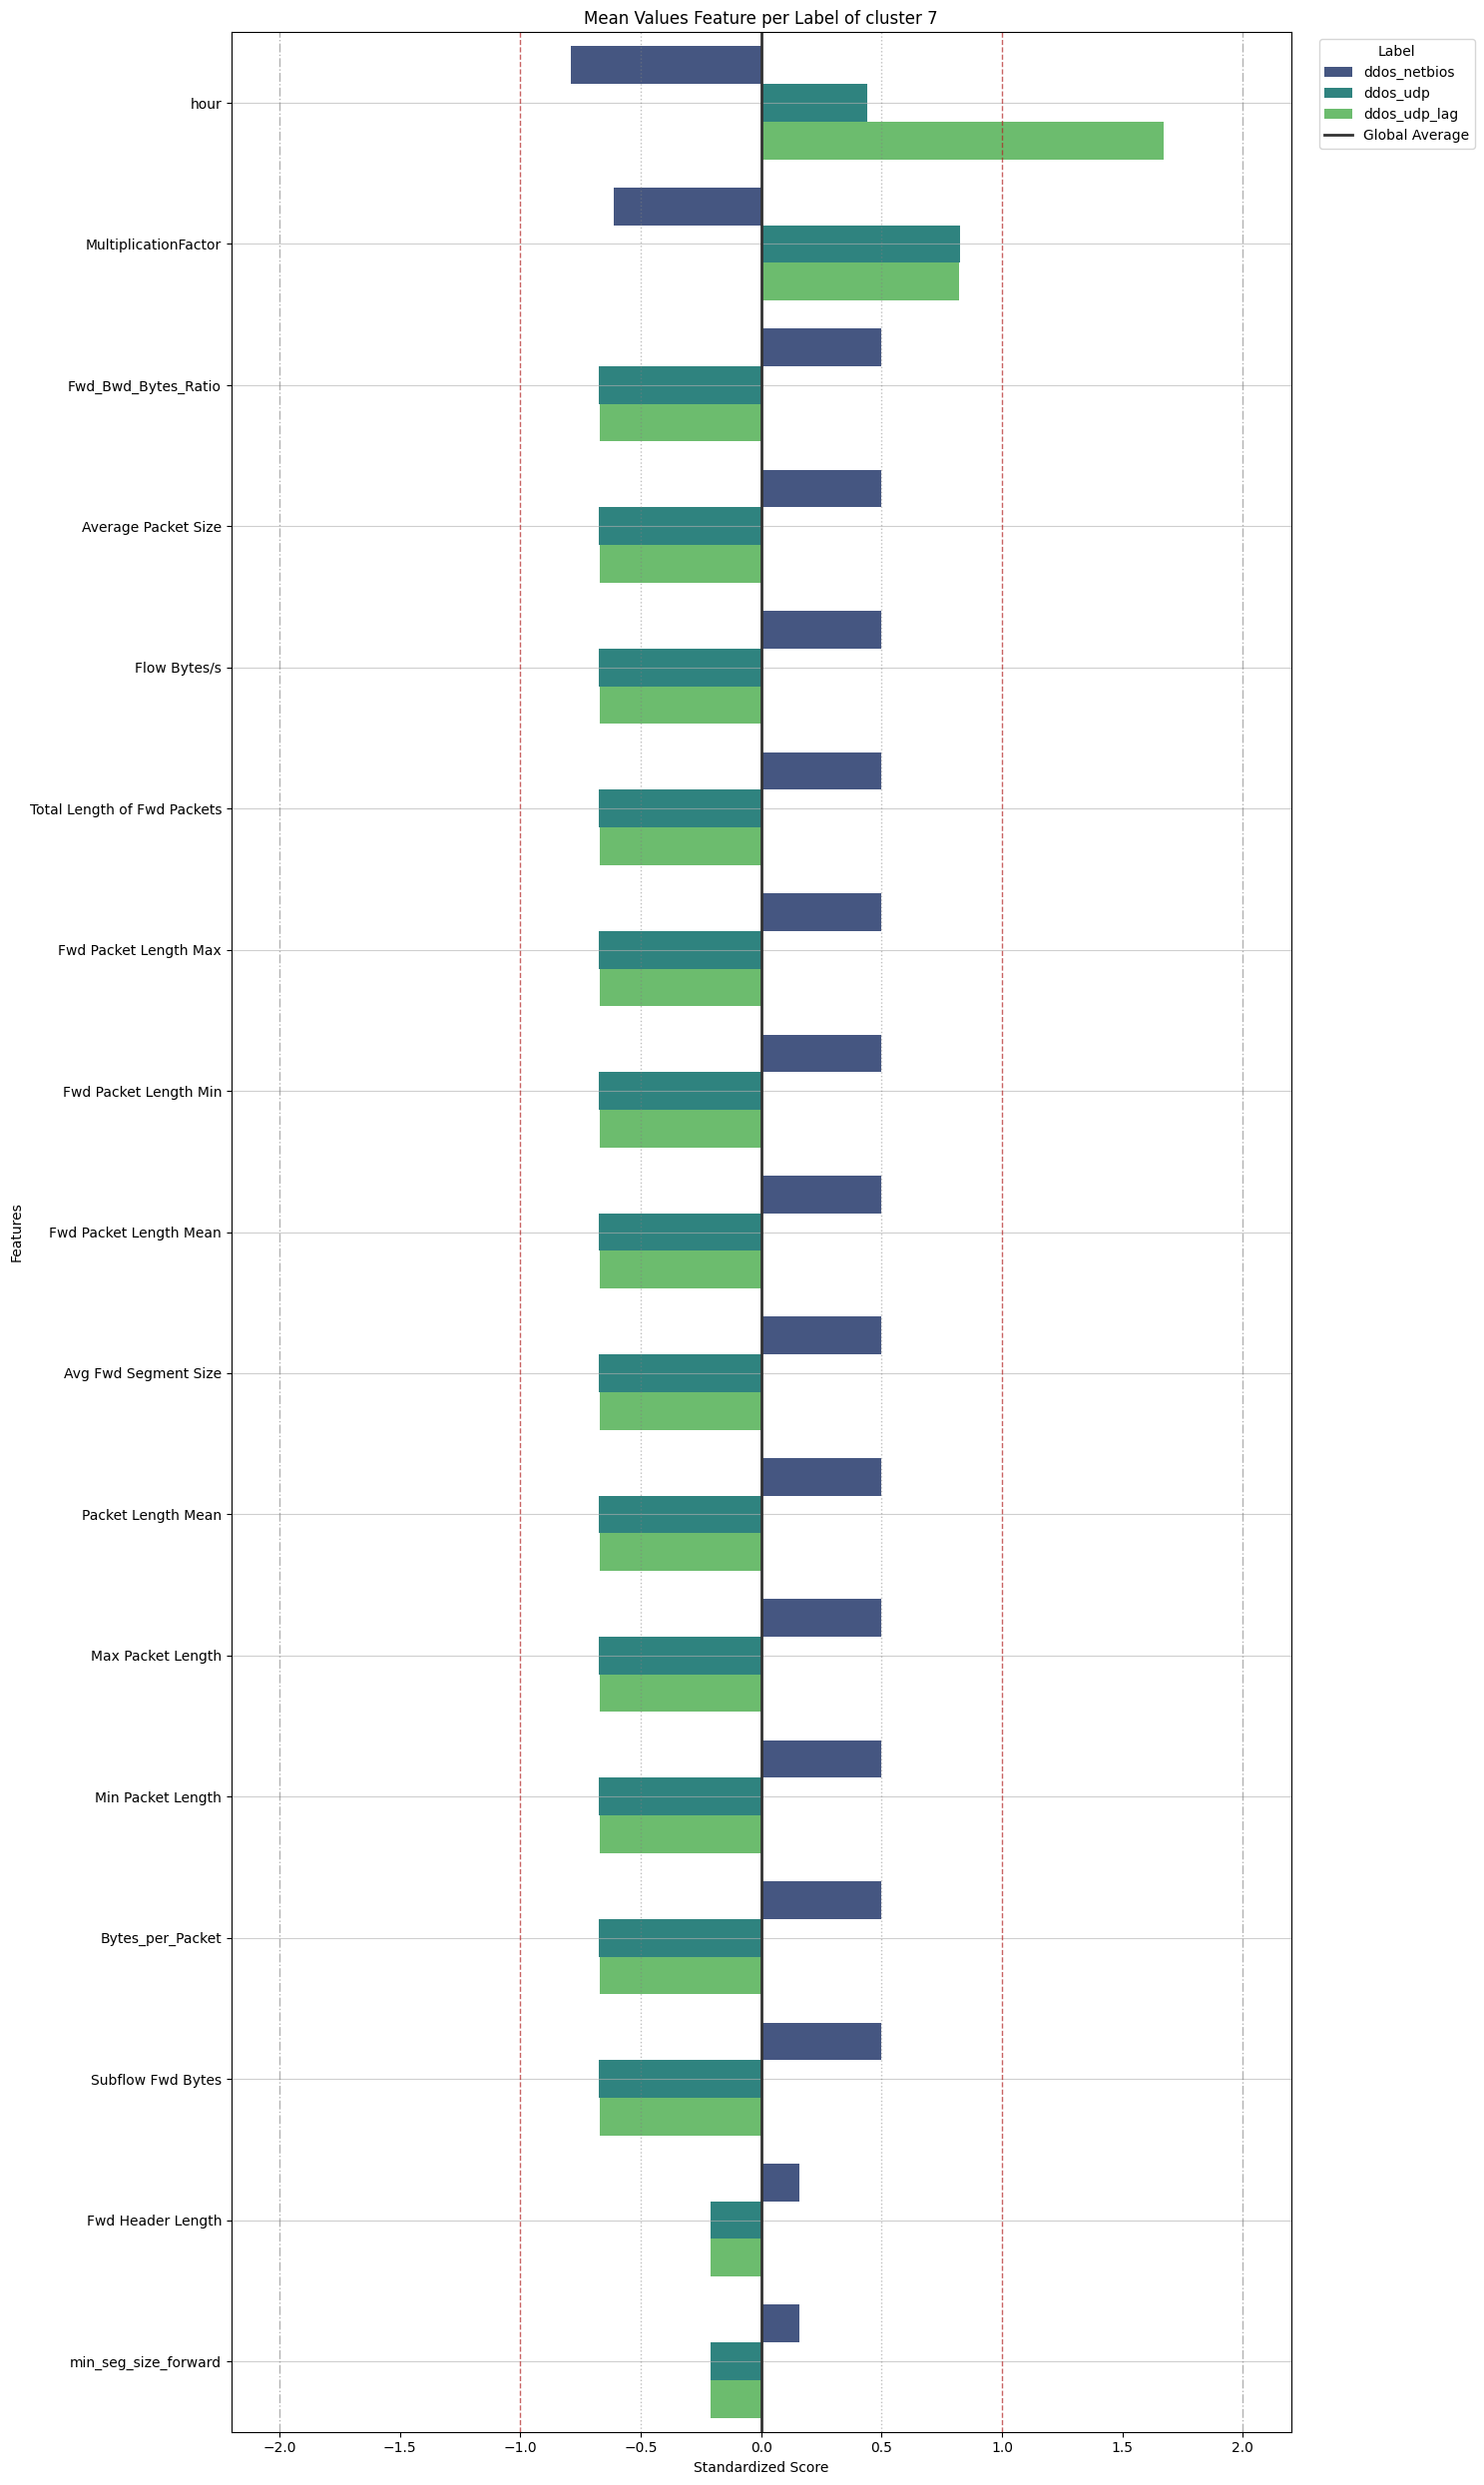

In [77]:
plotMeanFeaturesPerLabel(df_cluster_7_scaled, "Mean", 7)

### Attack Pattern Investigation – Cluster 3
Cluster 3 is another density-based region identified by DBSCAN, showing specific patterns of attack co-occurrence. The code extracts all samples assigned to cluster 3, visualizes the distribution of attack labels, removes less relevant labels, and analyzes the mean standardized feature values for each remaining attack type. The resulting plots highlight the feature-level similarities between different DDoS attack types that are grouped together in this cluster.

In [78]:
df_cluster_15 , df_cluster_15_scaled = getClusterDf(15)

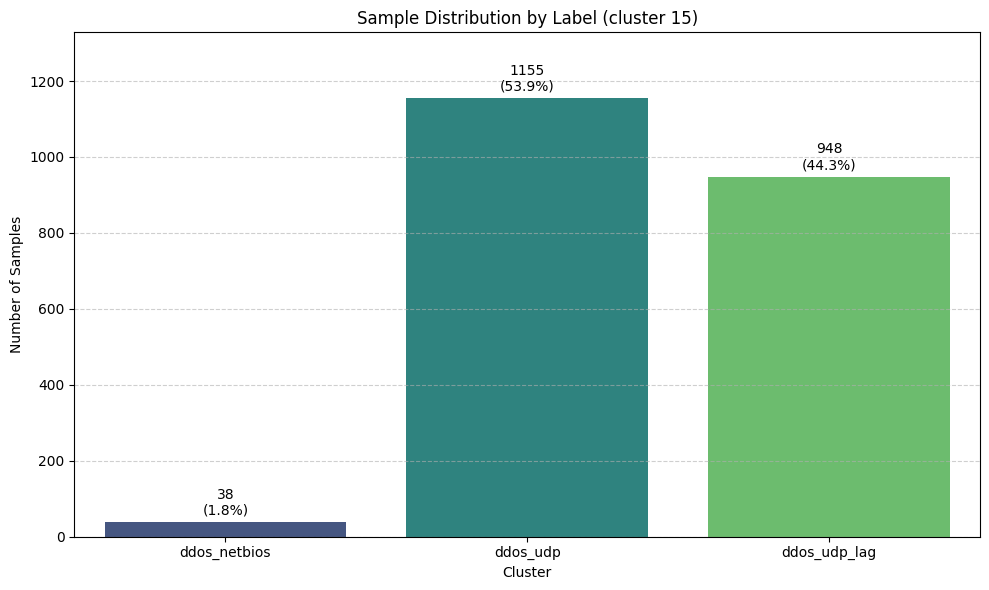

In [79]:
plotLabelSummary(df_cluster_15,15)

In [80]:
toDrop = ["ddos_benign", "ddos_netbios"]
df_cluster_15 = drop_Labels(df_cluster_15, toDrop)
df_cluster_15_scaled = drop_Labels(df_cluster_15_scaled, toDrop)

In [81]:
df_cluster_15.groupby("label").agg(["mean", "std", "median"])

Flow Duration                          Total Fwd Packets  \
                       mean            std    median              mean   
label                                                                    
ddos_udp      162202.221645  172611.508489  108684.0          4.995671   
ddos_udp_lag  146024.974684  148672.726000  108564.0          4.725738   

                              Total Length of Fwd Packets               \
                   std median                        mean          std   
label                                                                    
ddos_udp      3.144550    4.0                 1778.096970  1139.682423   
ddos_udp_lag  2.741348    4.0                 1683.664557   986.116058   

                     Fwd Packet Length Max  ... IAT_std_on_mean  \
              median                  mean  ...          median   
label                                       ...                   
ddos_udp      1438.0            385.204329  ...        1.730955   
ddos_udp_lag  1438.0            385.181435  ...        1.730943   

             Fwd_Bwd_Packets_Ratio                              \
                              mean           std        median   
label                                                            
ddos_udp              4.995671e+12  3.144550e+12  4.000000e+12   
ddos_udp_lag          4.725738e+12  2.741348e+12  4.000000e+12   

             Fwd_Bwd_Bytes_Ratio                              hour              
                            mean           std        median  mean  std median  
label                                                                           
ddos_udp            1.778097e+15  1.139682e+15  1.438000e+15  12.0  0.0   12.0  
ddos_udp_lag        1.683665e+15  9.861161e+14  1.438000e+15  13.0  0.0   13.0  

[2 rows x 108 columns]

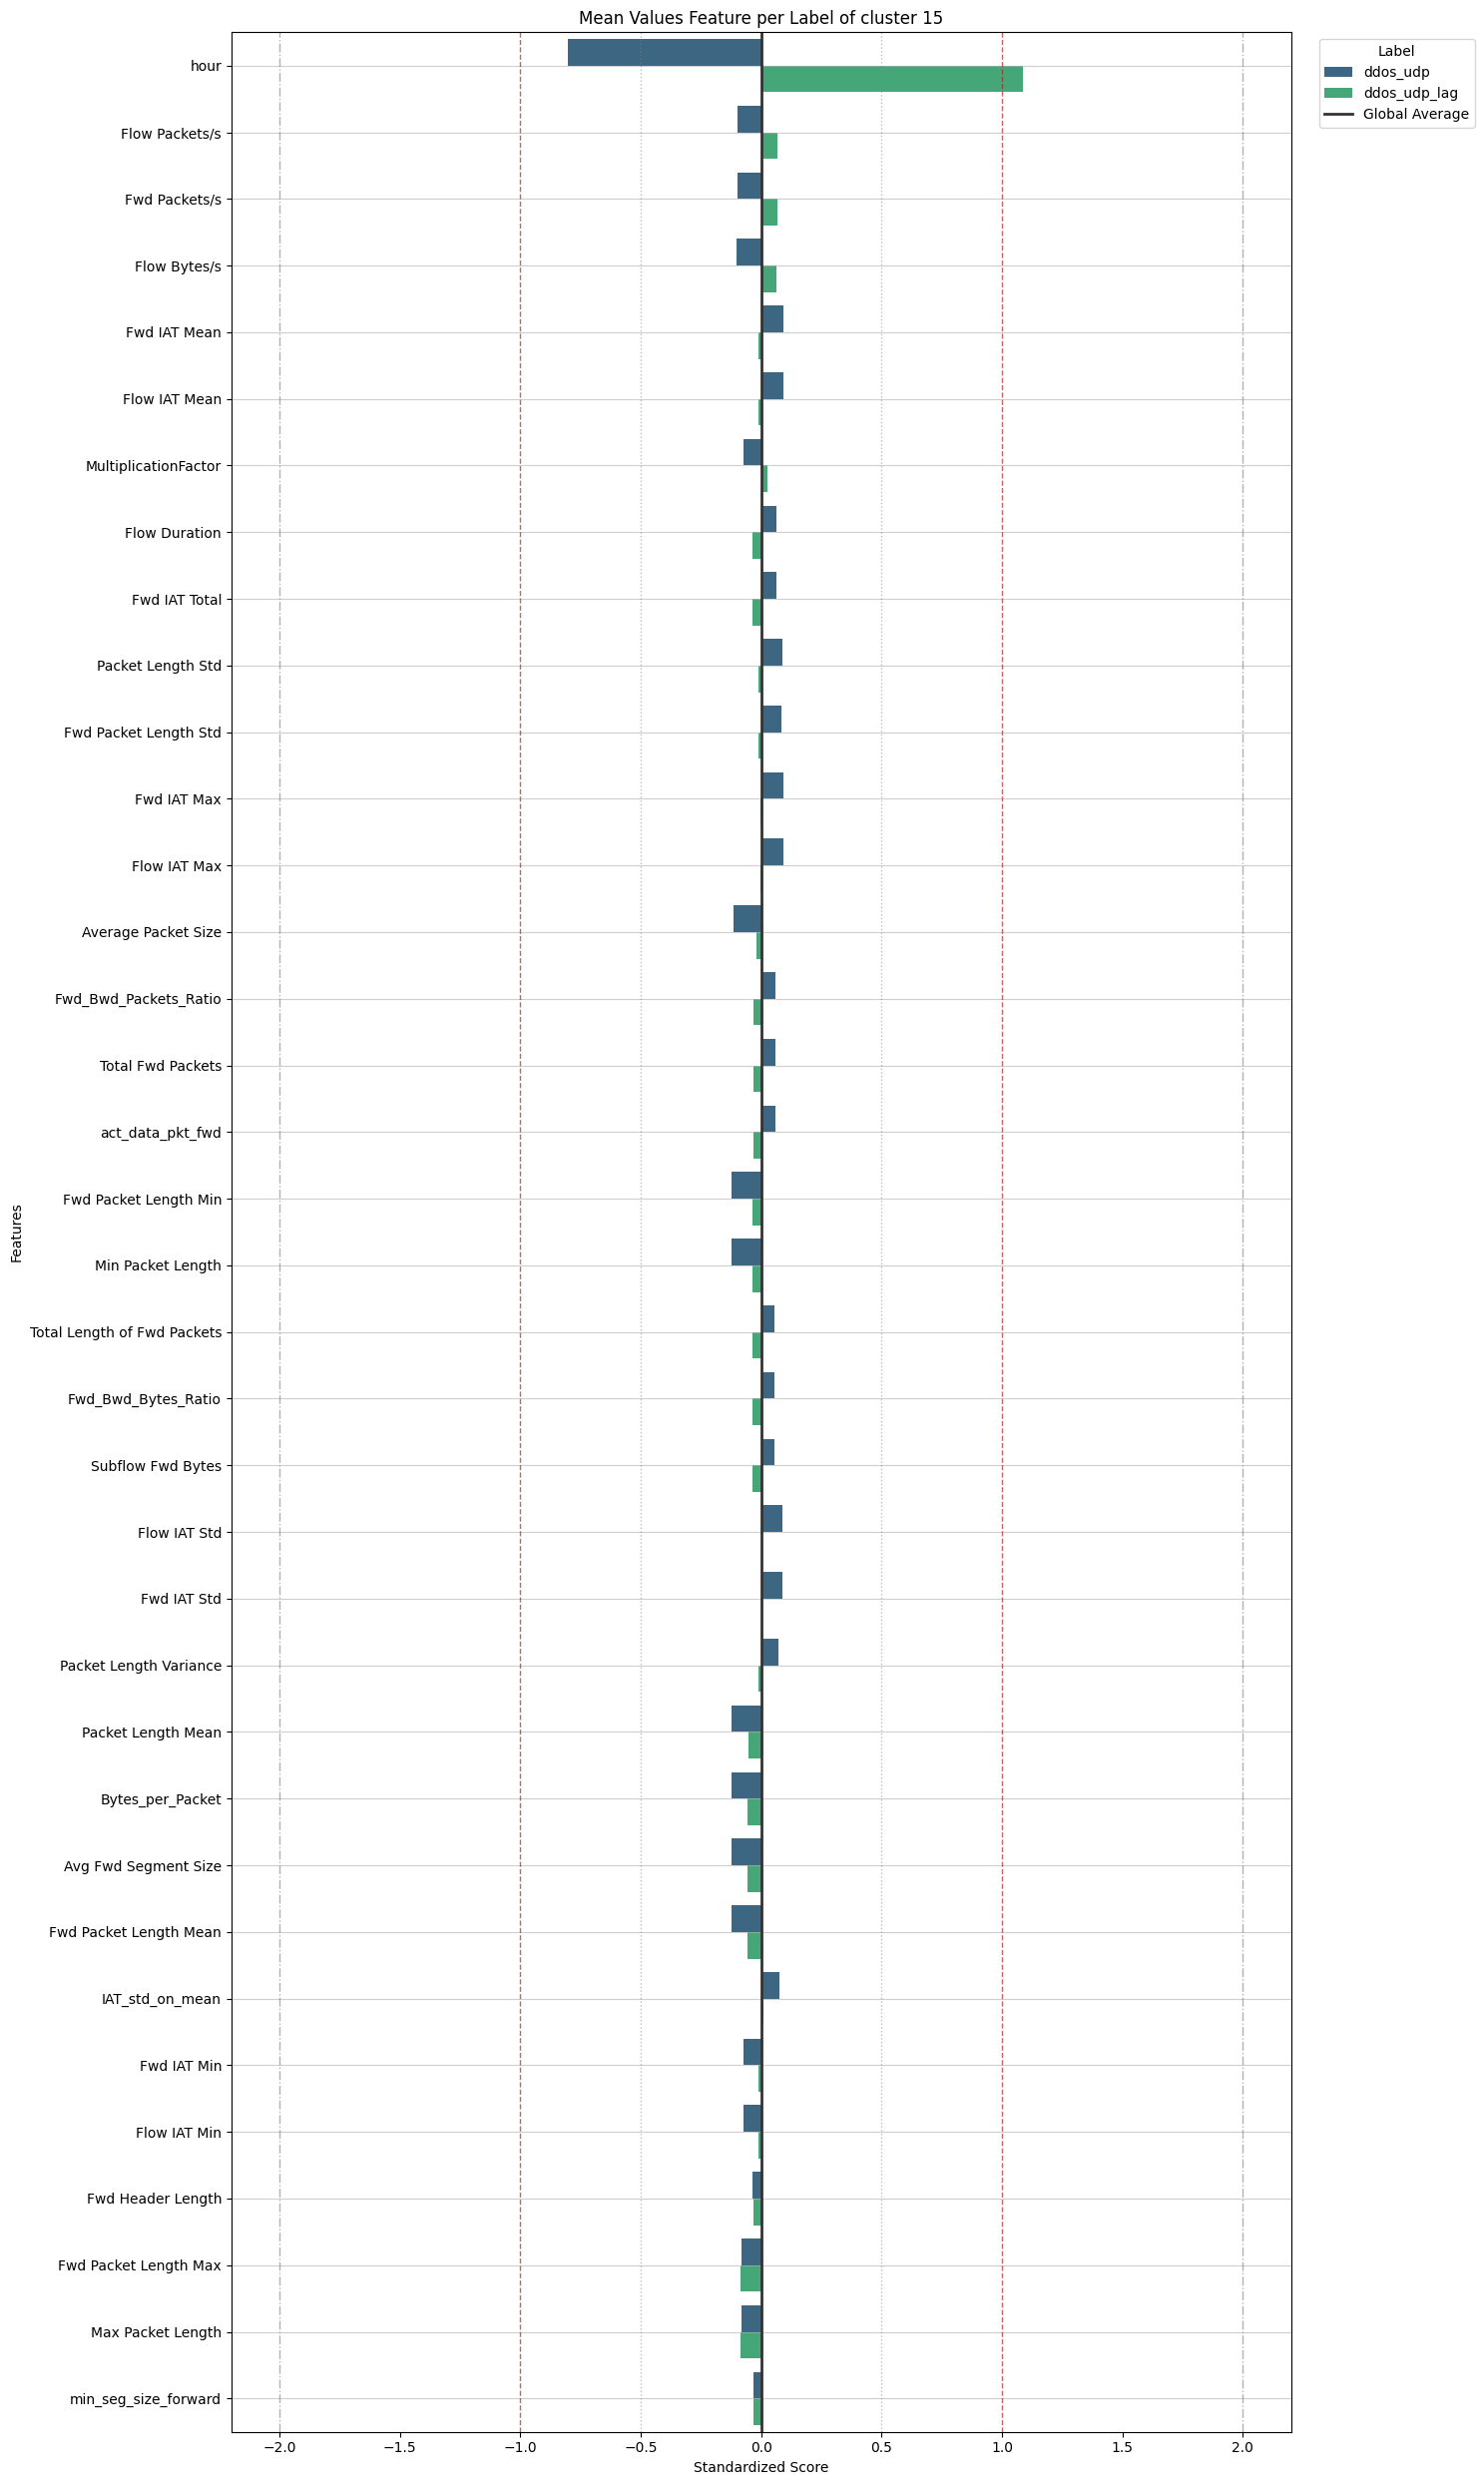

In [82]:
plotMeanFeaturesPerLabel(df_cluster_15_scaled, "Mean", 15)